# Exploratory Data Analysis: LA Metro Bike Share System

**Module Code**: CSMAD  
**Module Title**: Applied Data Science with Python  
**Assignment**: Coursework 1 - Exploratory Data Analysis  

**Date Completed**: November 13, 2025
**Hours Spent**: 35 hours  

In [1]:
# System and version check
import sys
print(sys.version)
!jupyter lab --version

3.11.7 | packaged by Anaconda, Inc. | (main, Dec 15 2023, 18:05:47) [MSC v.1916 64 bit (AMD64)]
4.0.11


In [2]:
#Libraries and Configuration block
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats


In [3]:
# Reusable code
def missing_value_summary(df):
    missing_count = df.isnull().sum()
    missing_pct = df.isnull().mean() * 100
    missing_summary = pd.DataFrame({
        'Missing Count': missing_count,
        'Missing %': missing_pct.round(2) })
    print(missing_summary[missing_summary['Missing Count'] > 0])
    return missing_summary


def barplot_anotation(barplot):
    for bar in barplot.patches:
        label = bar.get_x() + bar.get_width() / 2
        value = bar.get_height()
        barplot.text(label, value + 1, f"{value:.2f}%", color='black', ha='center', fontweight='bold')


## 1.Data Overview and Quality Assessment

### 1.1 Data Overview

In [4]:
# Load dataset
df = pd.read_csv('metro.csv', low_memory=False)
df_original = df.copy()

# Display dataframe info
print('\nDataframe Information:\n')
df.info()

# Display first 5 rows
print('\nFirst 5 rows:\n')
display(df.head())

# Display descriptive statistics
print('\nDescriptive Statistics:\n')
display(df.describe().round(2))

# Duration Statistics
print('\nDuration Statistics:\n')
print(f'Mean: {df["duration"].mean():.2f}min | Median: {df["duration"].median():.0f}min | Skewness: {df["duration"].skew() } |  Std: {df["duration"].std():.2f},')


Dataframe Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 92124 entries, 0 to 92123
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   trip_id              92124 non-null  int64  
 1   duration             92124 non-null  int64  
 2   start_time           92124 non-null  object 
 3   end_time             92124 non-null  object 
 4   start_station        92124 non-null  int64  
 5   start_lat            89985 non-null  float64
 6   start_lon            89985 non-null  float64
 7   end_station          92124 non-null  int64  
 8   end_lat              88052 non-null  float64
 9   end_lon              88052 non-null  float64
 10  bike_id              92124 non-null  object 
 11  plan_duration        92124 non-null  int64  
 12  trip_route_category  92124 non-null  object 
 13  passholder_type      92124 non-null  object 
 14  bike_type            92124 non-null  object 
dtypes: float64(

,trip_id,duration,start_time,end_time,start_station,start_lat,start_lon,end_station,end_lat,end_lon,bike_id,plan_duration,trip_route_category,passholder_type,bike_type
0,124657107,5,7/1/2019 0:04,7/1/2019 0:09,4312,34.066990,-118.290878,4410,34.063351,-118.296799,6168,30,One Way,Monthly Pass,standard
1,124657587,9,7/1/2019 0:07,7/1/2019 0:16,3066,34.063389,-118.236160,3066,34.063389,-118.236160,17584,30,Round Trip,Monthly Pass,electric
2,124658068,5,7/1/2019 0:20,7/1/2019 0:25,4410,34.063351,-118.296799,4312,34.066990,-118.290878,18920,30,One Way,Monthly Pass,electric
3,124659747,20,7/1/2019 0:44,7/1/2019 1:04,3045,34.028511,-118.256668,4275,34.012520,-118.285896,6016,1,One Way,Walk-up,standard
4,124660227,27,7/1/2019 0:44,7/1/2019 1:11,3035,34.048401,-118.260948,3049,34.056969,-118.253593,5867,30,One Way,Monthly Pass,standard



Descriptive Statistics:



,trip_id,duration,start_station,start_lat,start_lon,end_station,end_lat,end_lon,plan_duration
count,9.212400e+04,92124.00,92124.00,89985.00,89985.00,92124.00,88052.00,88052.00,92124.00
mean,1.274286e+08,33.17,3484.90,34.03,-118.29,3480.27,34.03,-118.29,60.29
std,1.524134e+06,129.06,611.48,0.06,0.07,609.94,0.06,0.07,111.14
min,1.246571e+08,1.00,3000.00,33.71,-118.50,3000.00,33.71,-118.50,1.00
25%,1.261375e+08,6.00,3029.00,34.04,-118.28,3028.00,34.04,-118.28,1.00
50%,1.274911e+08,12.00,3062.00,34.05,-118.26,3062.00,34.05,-118.26,30.00
75%,1.287379e+08,22.00,4285.00,34.05,-118.25,4285.00,34.05,-118.25,30.00
max,1.303877e+08,1440.00,4453.00,34.18,-118.23,4453.00,34.18,-118.23,999.00



Duration Statistics:

Mean: 33.17min | Median: 12min | Skewness: 9.282108945274391 |  Std: 129.06,


### 1.2 Categorical data overview

In [5]:
print('\nCATEGORICAL ANALYSIS:')

# Display unique value counts
print('\nUnique values count per column:\n')
print(df.nunique())

# Trip Route distribution
print('\nTrip Route:\n')
print(df['trip_route_category'].value_counts(normalize=True).mul(100).round(2))

# Passholder Type distribution
print('\nPassholder Type:\n')
print(df['passholder_type'].value_counts(normalize=True).mul(100).round(2))

# Bike Type distribution
print('\nBike Type:\n')
print(df['bike_type'].value_counts(normalize=True).mul(100).round(2))

# Plan Duration distribution
print('\nPlan Duration Type:\n')
print(df['plan_duration'].value_counts(normalize=True).mul(100).round(2))




CATEGORICAL ANALYSIS:

Unique values count per column:

trip_id                92124
duration                 857
start_time             57274
end_time               55658
start_station            183
start_lat                180
start_lon                179
end_station              183
end_lat                  180
end_lon                  179
bike_id                 2042
plan_duration              4
trip_route_category        2
passholder_type            6
bike_type                  3
dtype: int64

Trip Route:

trip_route_category
One Way       83.33
Round Trip    16.67
Name: proportion, dtype: float64

Passholder Type:

passholder_type
Monthly Pass    62.06
Walk-up         25.51
Annual Pass      6.75
One Day Pass     5.62
Testing          0.05
Flex Pass        0.01
Name: proportion, dtype: float64

Bike Type:

bike_type
electric    50.42
standard    32.00
smart       17.59
Name: proportion, dtype: float64

Plan Duration Type:

plan_duration
30     62.07
1      26.67
365    11.21
999

### 1.3 Data Quality Assessment

#### 1.3.1 Duplicate data check

In [6]:
# Check for duplicate rows
print('\nDuplicate counts:\n')
duplicate = df.duplicated().sum()
print(f'Number of duplicated rows: {duplicate}')


Duplicate counts:

Number of duplicated rows: 0


#### 1.3.2 Missing values check

In [7]:
# Check for missing values per column
print('\nMissing Data:\n')
missing = df.isnull().sum()
print(missing[missing > 0])

# Count rows with any missing values
num_missing_rows = df.shape[0] - df.dropna().shape[0]
print(f"\nNumber of rows with any missing values: {num_missing_rows}")


Missing Data:

start_lat    2139
start_lon    2139
end_lat      4072
end_lon      4072
dtype: int64

Number of rows with any missing values: 5364


In [8]:
# Combine start and end stations
stations = pd.concat([
    df[['start_station', 'start_lat', 'start_lon']].rename(columns={'start_station': 'station', 'start_lat': 'lat', 'start_lon': 'lon'}),
    df[['end_station', 'end_lat', 'end_lon']].rename(columns={'end_station': 'station', 'end_lat': 'lat', 'end_lon': 'lon'})
], ignore_index=True)

# Count missing coordinates per station
missing_counts = stations.groupby('station')[['lat', 'lon']].apply(lambda x: x.isna().sum())

# Filter stations with missing coordinates
missing_counts = missing_counts[(missing_counts['lat'] > 0) | (missing_counts['lon'] > 0)]

print("Stations with missing coordinates:")
print(missing_counts)

Stations with missing coordinates:
          lat   lon
station            
3000     1468  1468
4285     3217  3217
4286     1526  1526


#### 1.3.3 Statistical outliers

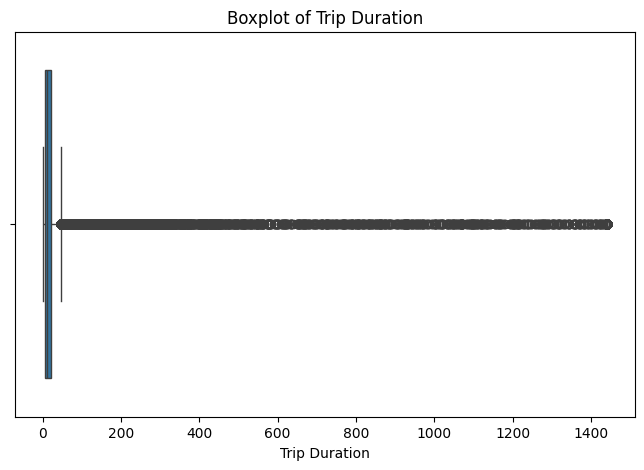

In [9]:
# Using boxplot to detect outliers 
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['duration'])
plt.title('Boxplot of Trip Duration')
plt.xlabel('Trip Duration')
plt.show()

**Observation** : The large number of points beyond the right whisker suggests many statistical outliers in trip duration, which may need further investigation.

**data overview visuals**:
the insight of the visuals is in the key findings

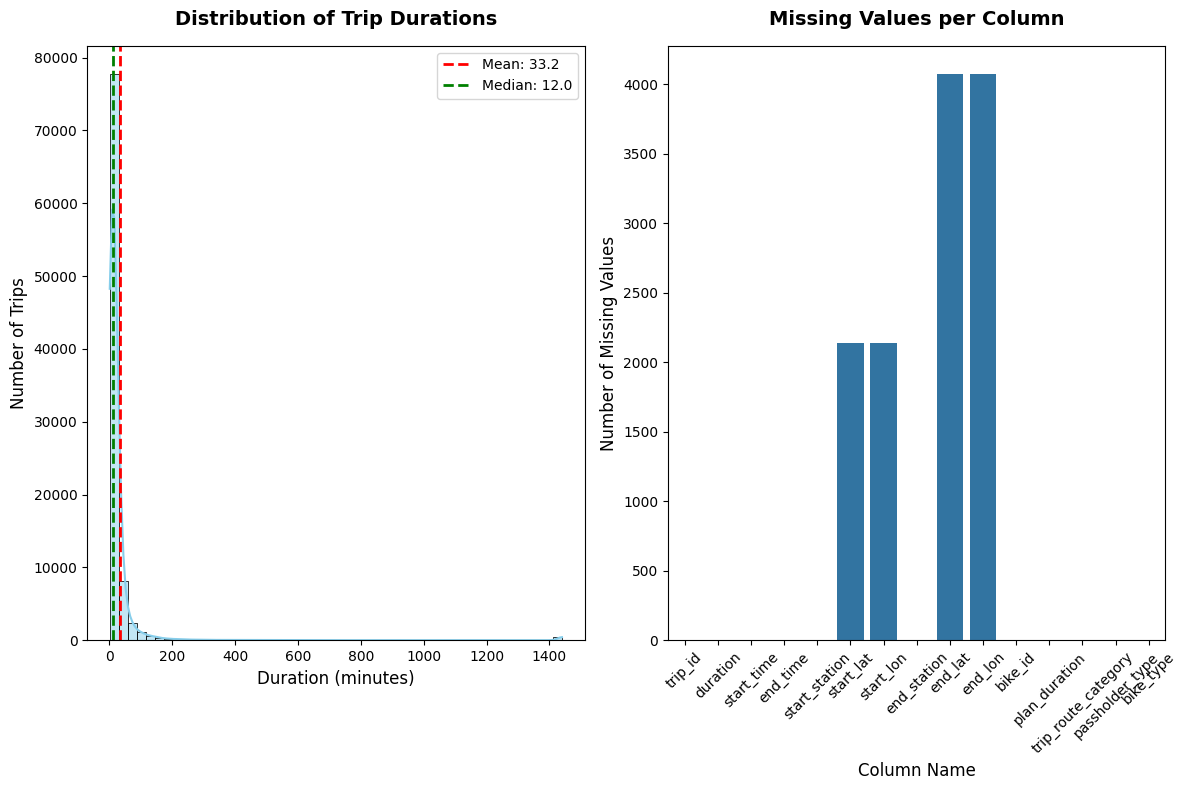

In [10]:
fig, axis = plt.subplots(1, 2, figsize=(12, 8))

# Histogram trip duration distribution on first subplot (axis[0])
sns.histplot(df['duration'], bins=50, color='skyblue', edgecolor='black', kde=True, ax=axis[0])
axis[0].set_title("Distribution of Trip Durations", fontsize=14, fontweight='bold', pad=15)
axis[0].set_xlabel("Duration (minutes)", fontsize=12)
axis[0].set_ylabel("Number of Trips", fontsize=12)

mean_duration = df["duration"].mean()
median_duration = df["duration"].median()

# reference lines for mean and median Histogram ax0
axis[0].axvline(mean_duration, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_duration:.1f}')
axis[0].axvline(median_duration, color='green', linestyle='--', linewidth=2, label=f'Median: {median_duration:.1f}')
axis[0].legend()

# Bar chart of missing values on second subplot (axis[1])
sns.barplot(x=missing.index, y=missing.values, ax=axis[1])
axis[1].set_title("Missing Values per Column", fontsize=14, fontweight='bold', pad=15)
axis[1].set_xlabel("Column Name", fontsize=12)
axis[1].set_ylabel("Number of Missing Values", fontsize=12)
axis[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


**Observation**: Trip durations are mostly short with many long-duration outliers. Missing values mainly occur in station longitude and latitude columns.

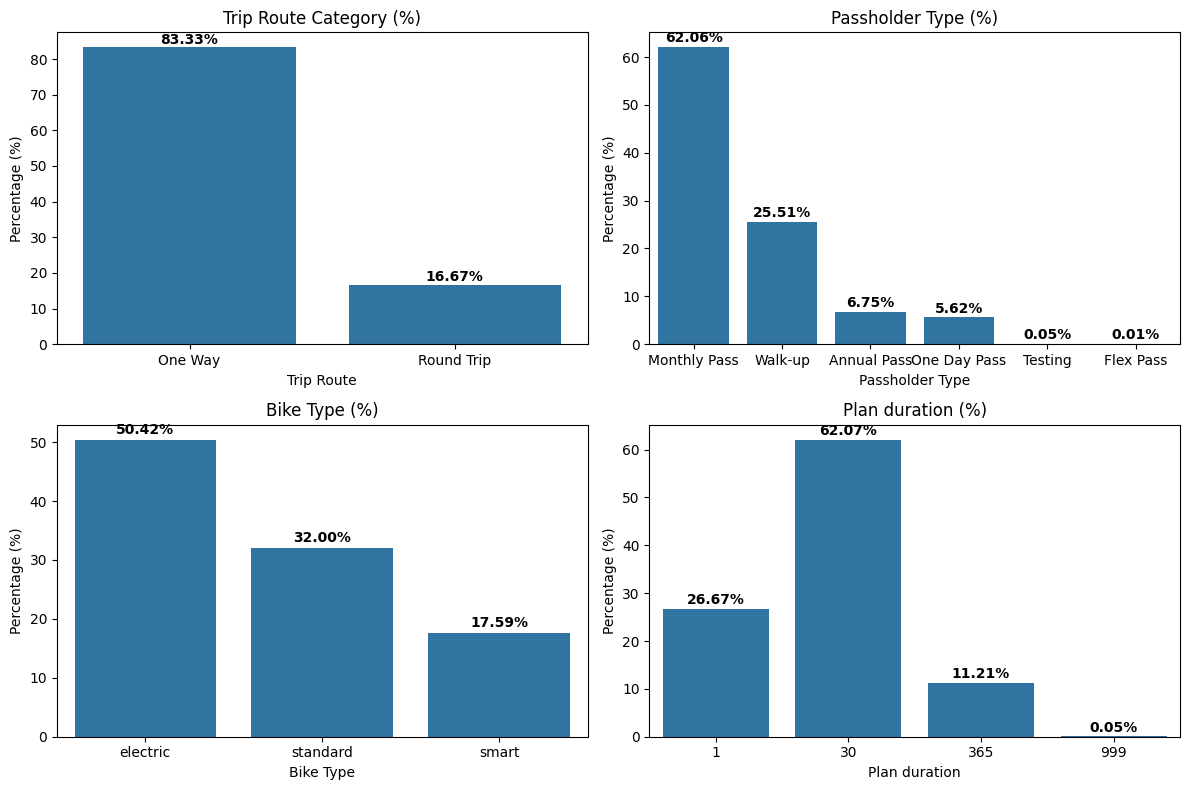

In [11]:
# Prepare your category proportions, as before
trip_route_pct = df['trip_route_category'].value_counts(normalize=True).mul(100).round(2)
passholder_pct = df['passholder_type'].value_counts(normalize=True).mul(100).round(2)
bike_type_pct = df['bike_type'].value_counts(normalize=True).mul(100).round(2)
plan_duration_pct = df['plan_duration'].value_counts(normalize=True).mul(100).round(2)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Trip Route
barplot = sns.barplot(x=trip_route_pct.index, y=trip_route_pct.values, ax=axes[0, 0])
axes[0, 0].set_title("Trip Route Category (%)")
axes[0, 0].set_xlabel("Trip Route")
axes[0, 0].set_ylabel("Percentage (%)")
barplot_anotation(barplot)

# Passholder Type
barplot = sns.barplot(x=passholder_pct.index, y=passholder_pct.values, ax=axes[0, 1])
axes[0, 1].set_title("Passholder Type (%)")
axes[0, 1].set_xlabel("Passholder Type")
axes[0, 1].set_ylabel("Percentage (%)")
barplot_anotation(barplot)

# Bike Type
barplot = sns.barplot(x=bike_type_pct.index, y=bike_type_pct.values, ax=axes[1, 0])
axes[1, 0].set_title("Bike Type (%)")
axes[1, 0].set_xlabel("Bike Type")
axes[1, 0].set_ylabel("Percentage (%)")
barplot_anotation(barplot)

# Plan duraation
barplot = sns.barplot(x=plan_duration_pct.index, y=plan_duration_pct.values, ax=axes[1, 1])
axes[1, 1].set_title("Plan duration (%)")
axes[1, 1].set_xlabel("Plan duration")
axes[1, 1].set_ylabel("Percentage (%)")
barplot_anotation(barplot)

plt.tight_layout()
plt.show()

**Key Findings:**
**Overview**
- Dataset contains **92,124 records** and **15 attributes**
- Most trips are **one-way (83.3%)**  
- **Monthly pass holders** represent **62.1%** of users  
- **Electric bikes** are used in **50.4%** of trips  
- Trip durations are **right-skewed** (mean: 33 min, median: 12 min), reflecting mostly short commutes  
**Data Quality**
- Missing coordinates occur only at **three ghost stations** `3000`,`4285`,`4286` with no location data.
- **No duplicate rows**; all trip records are unique.
- All other stations have complete coordinates
- **Outliers** the boxplot provides clear evidence of both extreme values and strong right-skewness. These findings justify further analysis and careful outlier handling in any downstream work. 

## 2.Data Cleansing and Preprocessing

### 2.1 Irregularities (duplicates, datatype, invalid values)
**duplicates**: dataset has no duplicates

#### 2.1.1 Datatype

In [12]:
# Define column types
datetime_cols = ['start_time', 'end_time']
numeric_cols = ['start_lat', 'start_lon', 'end_lat', 'end_lon', 'duration']
categorical_cols = ['passholder_type', 'trip_route_category', 'bike_type', 'plan_duration']

# Convert datetime columns
for col in datetime_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col])

# Convert numeric columns
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Standardize categorical columns
for col in categorical_cols:
    if col in df.columns:
        df[col] = df[col].astype(str).str.lower().str.strip()
        print(f'\n{col} values:')
        print(df[col].unique())

print('\nResult after datatype correction and standardization:\n')
print(df.dtypes)



passholder_type values:
['monthly pass' 'walk-up' 'annual pass' 'one day pass' 'flex pass'
 'testing']

trip_route_category values:
['one way' 'round trip']

bike_type values:
['standard' 'electric' 'smart']

plan_duration values:
['30' '1' '365' '999']

Result after datatype correction and standardization:

trip_id                         int64
duration                        int64
start_time             datetime64[ns]
end_time               datetime64[ns]
start_station                   int64
start_lat                     float64
start_lon                     float64
end_station                     int64
end_lat                       float64
end_lon                       float64
bike_id                        object
plan_duration                  object
trip_route_category            object
passholder_type                object
bike_type                      object
dtype: object


**Justification :** 
- DateTime: Enables temporal feature extraction for pattern analysis.
- Numeric (errors='coerce'): Converts invalid values to NaN safely.
- Categorical: Standardizes text to prevent duplicates.


#### 2.1.2 Invalid values

In [13]:
# Remove negative durations
if 'duration' in df.columns:
    before = df.shape[0]
    df = df[df['duration'] >= 0]
    after = df.shape[0]
    print(f"Removed {before - after} rows with negative duration")

# Replace invalid plan_duration values with NaN
if 'plan_duration' in df.columns:
    valid_values = ['1', '30', '365']
    df.loc[~df['plan_duration'].isin(valid_values), 'plan_duration'] = np.nan
    print(f"Plan duration unique values:\n{df['plan_duration'].unique()}")

Removed 0 rows with negative duration
Plan duration unique values:
['30' '1' '365' nan]


**Justification :** The value 999 in plan_duration is invalid, so I replace it with NaN to keep trip data and allow later mode-based imputation.

#### 2.1.3 timestamp validation 


In [14]:
# Remove rows where end_time is before start_time
if {'start_time', 'end_time'}.issubset(df.columns):
    before = df.shape[0]
    df = df[df['end_time'] >= df['start_time']]
    after = df.shape[0]
    print(f"Removed {before - after} rows where end_time < start_time")

Removed 0 rows where end_time < start_time


#### 2.1.4 Coordination validation

In [15]:

# Check coordinate column types
print(df[['start_lat', 'start_lon', 'end_lat', 'end_lon']].dtypes)

# Remove impossible coordinates (lat: -90 to 90, lon: -180 to 180)
if {'start_lat', 'start_lon', 'end_lat', 'end_lon'}.issubset(df.columns):
    before = df.shape[0]
    df = df[
        df['start_lat'].between(-90, 90) &
        df['start_lon'].between(-180, 180) &
        df['end_lat'].between(-90, 90) &
        df['end_lon'].between(-180, 180)
    ]
    after = df.shape[0]
    print(f"Removed {before - after} rows with impossible coordinates")

# Check remaining missing values
missing = df.isnull().sum()
print(missing[missing > 0])



start_lat    float64
start_lon    float64
end_lat      float64
end_lon      float64
dtype: object
Removed 5364 rows with impossible coordinates
plan_duration    27
dtype: int64


**Justification**:
Invalid coordinates (outside lat: -90–90, lon: -180–180) indicate data errors. Missing values come from ghost stations (3000, 4285, 4286) with no real locations:
- No reference for true positions
- Imputation would create false spatial data
Dropping these rows preserves data accuracy.

### 2.2 Missing Values

- Only the 27 newly created missing values in plan duration remain to be handled.


In [16]:
# Check missing values before
print("Missing values BEFORE:")
missing_value_summary(df)

# Fill missing values with mode (most frequent value)
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Check missing values after
print("\nMissing values AFTER:")
missing_value_summary(df)


Missing values BEFORE:
               Missing Count  Missing %
plan_duration             27       0.03

Missing values AFTER:
Empty DataFrame
Columns: [Missing Count, Missing %]
Index: []


,Missing Count,Missing %
trip_id,0,0.0
duration,0,0.0
start_time,0,0.0
end_time,0,0.0
start_station,0,0.0
start_lat,0,0.0
start_lon,0,0.0
end_station,0,0.0
end_lat,0,0.0
end_lon,0,0.0


**Justification :**
Mode imputation was used for plan_duration because:
- It’s a categorical (1, 30, 365)
- The mode (30-day) reflects typical user behavior (62% of trips)
- Only 27,impact is minimal

### 2.3 Outliers

#### 2.3.1 Outliers Detection

##### 2.3.1 Visualizing trip durations by trip type and bike type:

**Boxplot:** Shows the distribution of trip durations for `One Way` vs `Round Trip` trips, further separated by `bike_type`. Outliers appear as points outside the whiskers.  


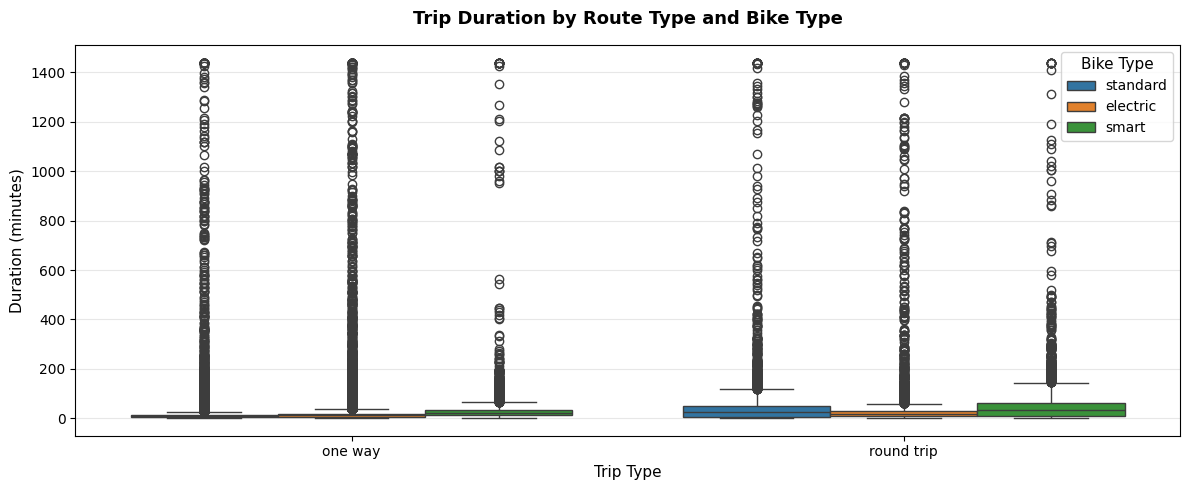

In [17]:
# Create boxplot - trip duration by route type and bike type
fig, ax= plt.subplots(figsize=(12,5))
sns.boxplot(x='trip_route_category', y='duration', hue='bike_type', data=df)
ax.set_title("Trip Duration by Route Type and Bike Type", fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel("Duration (minutes)", fontsize=11)
ax.set_xlabel("Trip Type", fontsize=11)
ax.legend(title='Bike Type', fontsize=10, title_fontsize=11)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


**Observation**: Trip duration varies by trip type and bike type, with many long-duration outliers across all categories.

##### 3.1.2 Visualizing trip durations distribution:
**Histogram:** Displays the overall distribution of trip durations, with a KDE curve to illustrate skewness.

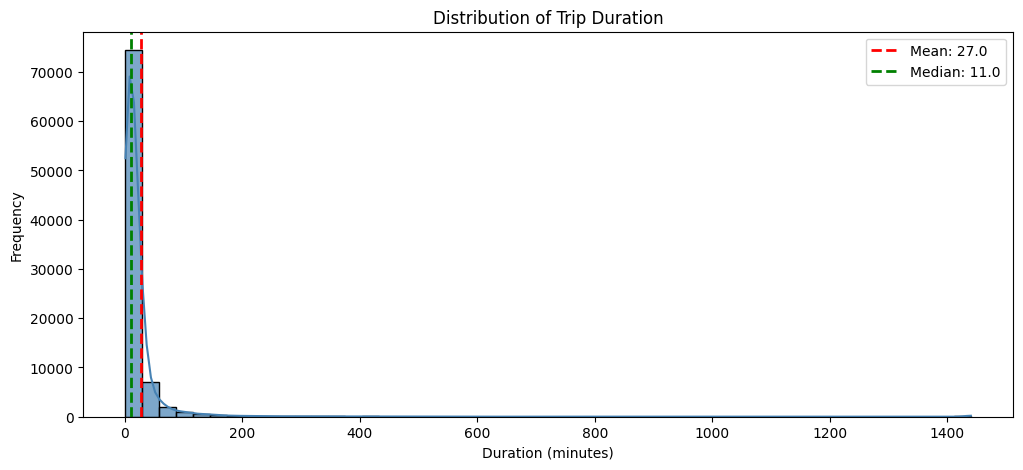

Mean: 27.00 min | Median: 11.00 min | Std: 95.72


In [18]:
# Create histogram with KDE curve
plt.figure(figsize=(12, 5))
sns.histplot(df['duration'], bins=50, kde=True, color='steelblue', edgecolor='black', alpha=0.7)
plt.title("Distribution of Trip Duration")
plt.xlabel("Duration (minutes)")
plt.ylabel("Frequency")

# Calculate mean and median
mean_duration = df['duration'].mean()
median_duration = df['duration'].median()

# Add reference lines for mean and median
plt.axvline(mean_duration, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_duration:.1f}')
plt.axvline(median_duration, color='green', linestyle='--', linewidth=2, label=f'Median: {median_duration:.1f}')

plt.legend()
plt.show()

# Print summary statistics
print(f"Mean: {mean_duration:.2f} min | Median: {median_duration:.2f} min | Std: {df['duration'].std():.2f}")


**Observation**: The trip duration distrubution is right skewed due to high volum of outliers 

#### 3.2 Outlier handling:

In [19]:
# Remove unrealistic durations (domain knowledge)
if 'duration' in df.columns:
    before = df.shape[0]
    df = df[(df['duration'] <= 24 * 60) & (df['duration'] > 3)]
    after = df.shape[0]
    print(f"Removed {before - after} rows with unrealistic durations")

Removed 8788 rows with unrealistic durations


**Justification – Domain Rules:**
Lower bound (3 minutes): Trips under 3 minutes are implausible because:
- Unlocking, riding, and docking take longer.
- Stations are spaced beyond such short travel times.
- Likely represent errors or immediate re-docks.
Upper bound (24 hours / 1440 minutes): Trips over 24 hours indicate:
- Unreturned, lost, or stolen bikes.
- Timestamp or docking errors.
- Policy violations in typical bike-share systems.
These bounds retain realistic trips while removing anomalies that could distort analysis.

In [20]:
# Remove outliers using IQR method
if 'duration' in df.columns:
    before = df.shape[0]
    Q1 = df['duration'].quantile(0.25)
    Q3 = df['duration'].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    df = df[df['duration'].between(lower_bound, upper_bound)]
    after = df.shape[0]
    print(f"Removed {before - after} outliers using IQR method")


Removed 6866 outliers using IQR method


**Justification  IQR method:**
After domain filtering, the IQR method (1.5× rule) was applied because:
- It’s a standard statistical approach that removes extreme outliers while keeping valid long trips
- The right-skewed distribution (mean 33 min, median 12 min) showed distortion from extreme values
- It adapts to the data’s actual spread instead of using arbitrary limits
Post-cleaning, trip durations better reflect typical commuter behavior.
The combined domain + IQR approach ensures both practical and statistical validity.

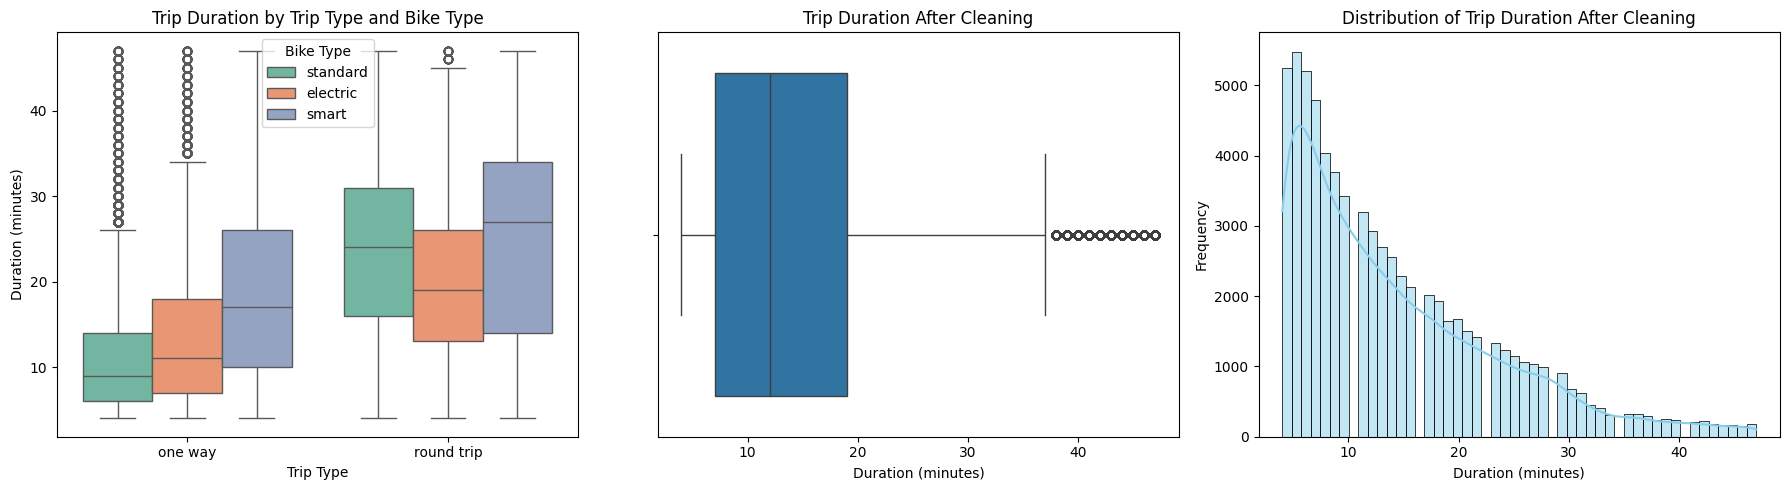


Duration Statistics:

Mean: 14.29min | Median: 12min | Skewness: 1.1451414426094921 |  Std: 9.29,


In [21]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Trip duration by route type and bike type
sns.boxplot(x='trip_route_category', y='duration', hue='bike_type', data=df, 
            palette='Set2', ax=axes[0])
axes[0].set_title("Trip Duration by Trip Type and Bike Type")
axes[0].set_ylabel("Duration (minutes)")
axes[0].set_xlabel("Trip Type")
axes[0].legend(title='Bike Type')

# Trip duration - single boxplot
sns.boxplot(x=df['duration'], ax=axes[1])
axes[1].set_title("Trip Duration After Cleaning")
axes[1].set_xlabel("Duration (minutes)")

# Trip duration histogram
sns.histplot(df['duration'], bins=50, kde=True, color='skyblue', ax=axes[2])
axes[2].set_title("Distribution of Trip Duration After Cleaning")
axes[2].set_xlabel("Duration (minutes)")
axes[2].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

# Duration Statistics
print('\nDuration Statistics:\n')
print(f'Mean: {df["duration"].mean():.2f}min | Median: {df["duration"].median():.0f}min | Skewness: {df["duration"].skew() } |  Std: {df["duration"].std():.2f},')

**Observation** : 
- **Boxplots**: The combination of domain knowledge and statistical detection effectively removes extreme, unrealistic, and anomalous trip durations, while preserving plausible long trips that may still appear as outliers.
- **Hostogram**: The histogram shows that trip durations are right-skewed, indicating that most trips are short, typical of commuter behavior.


In [22]:
# Saving the clean file
df.to_csv('metro_cleaned.csv', index=False)
print(f"✓ Cleaned dataset saved: {len(df):,} records")

✓ Cleaned dataset saved: 71,106 records


### 4. Data Transformation & FEATURE ENGINEERING

#### 1.Extract temporal features
New features were derived to capture temporal patterns:
`start_hour`: hour of the day (0–23) for identifying peak commuting times.
`start_day`: day of the week (e.g., Monday, Tuesday) to analyze weekly patterns.
`start_month`: month of the year for seasonal trends.
`weekday`: numeric representation of the day (0=Monday, 6=Sunday).
`weekend`: boolean flag indicating if the trip occurred on a weekend (Saturday or Sunday).
These features enable aggregation, visualization, and pattern detection across different time scales.

In [23]:
df['start_hour'] = df['start_time'].dt.hour
df['start_day'] = df['start_time'].dt.day_name()
df['start_month'] = df['start_time'].dt.month
df['weekday'] = df['start_time'].dt.weekday  # 0=Monday, 6=Sunday
df['weekend'] = df['weekday'].isin([5,6])  # True if 05=Saturday/06=Sunday

**Justification:**
- start_hour: Identifies peak commuting (morning/evening) and off-peak leisure periods.
- start_day & weekday: Capture weekly patterns separating workday commutes from weekend recreation.
- start_month: Reveals seasonal trends influenced by weather or tourism.
- weekend (boolean): Simplifies weekday vs. weekend comparisons for analysis.
These features convert raw timestamps into meaningful variables that expose behavioral patterns not visible in the original datetime data.

#### 2.Log-transform 
`log_duration` = log(1 + duration) was created to reduce skew in the trip duration distribution.

In [24]:
df['log_duration'] = np.log1p(df['duration'])
skewness_log = df['log_duration'].skew()
print(f"Original skewness: 1.44")
print(f"Log-transformed skewness: {skewness_log:.2f}")

Original skewness: 1.44
Log-transformed skewness: 0.15


**Justification:**
reduces right-skew from 1.14 to 0.15, creating a symmetric distribution better suited for statistical modeling and visualization.

## 3.Data Visualisation

### 4.1 TEMPORAL PATTERNS - Peak Hours and Daily Trends
- We want to know: how many trips happen at each hour of each day?
- So we group by day of week AND hour, then count trips

start_hour   0    1   2   3   4   5    6    7    8    9   ...   14   15   16  \
start_day                                                 ...                  
Friday      129   68  33  11  21  44  260  412  669  504  ...  565  763  747   
Monday      106   54  31   7  19  78  333  513  716  509  ...  565  661  801   
Saturday    177  134  92  35  24  15   50  137  195  299  ...  564  592  538   
Sunday      195  112  75  32  15  22   36   98  142  286  ...  638  646  614   
Thursday     78   50  22   4  17  55  347  474  658  549  ...  549  648  815   
Tuesday     100   53  28  13  21  68  415  550  761  579  ...  527  671  844   
Wednesday   103   47  21  12  15  82  374  539  766  561  ...  522  690  704   

start_hour    17    18   19   20   21   22   23  
start_day                                        
Friday       929   840  745  562  448  319  259  
Monday      1068  1007  794  573  437  282  148  
Saturday     605   631  548  519  429  326  333  
Sunday       689   691  549  

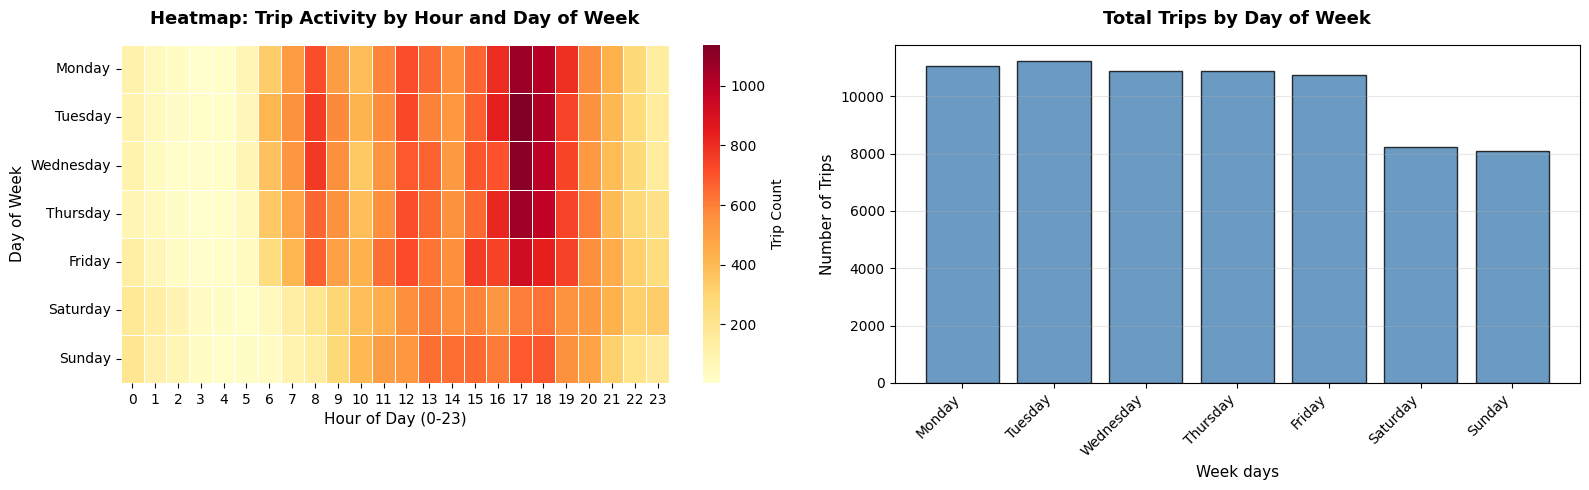


=== TEMPORAL PATTERNS INSIGHTS ===
Peak hour: 17H
Busiest day: Tuesday
Quietest day: Sunday


In [25]:
# 2x2 subplot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Aggregate data
hourly_daily_trips = df.groupby(['start_day', 'start_hour']).size().unstack(fill_value=0)
print(hourly_daily_trips)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
hourly_daily_trips = hourly_daily_trips.reindex(day_order)

# SUBPLOT 1: Heatmap
sns.heatmap(hourly_daily_trips, 
            cmap='YlOrRd', 
            ax=axes[0],
            cbar_kws={'label': 'Trip Count'},
            linewidths=0.5)

axes[0].set_title('Heatmap: Trip Activity by Hour and Day of Week', 
                   fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel('Hour of Day (0-23)', fontsize=11)
axes[0].set_ylabel('Day of Week', fontsize=11)

# SUBPLOT 2: Bar chart
daily_trip_count = df.groupby('start_day').size().reindex(day_order)

axes[1].bar(range(len(daily_trip_count)), 
            daily_trip_count.values, 
            color='steelblue', 
            edgecolor='black',
            alpha=0.8)

axes[1].set_title('Total Trips by Day of Week', 
                   fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel('Week days', fontsize=11)
axes[1].set_ylabel('Number of Trips', fontsize=11)
axes[1].set_xticks(range(len(daily_trip_count)))
axes[1].set_xticklabels(daily_trip_count.index, rotation=45, ha='right')
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()
print("\n=== TEMPORAL PATTERNS INSIGHTS ===")
print(f"Peak hour: {hourly_daily_trips.sum(axis=0).idxmax()}H")
print(f"Busiest day: {daily_trip_count.idxmax()}")
print(f"Quietest day: {daily_trip_count.idxmin()}")



**Observation**: Trip activity peaks during weekday afternoons and is lower on weekends. Most trips occur Monday to Friday, especially in the late afternoon hours.

### 4.2 PASSHOLDER TYPE - Usage Patterns & Duration Comparison
We want to understand: Do different passholder types use bikes differently?

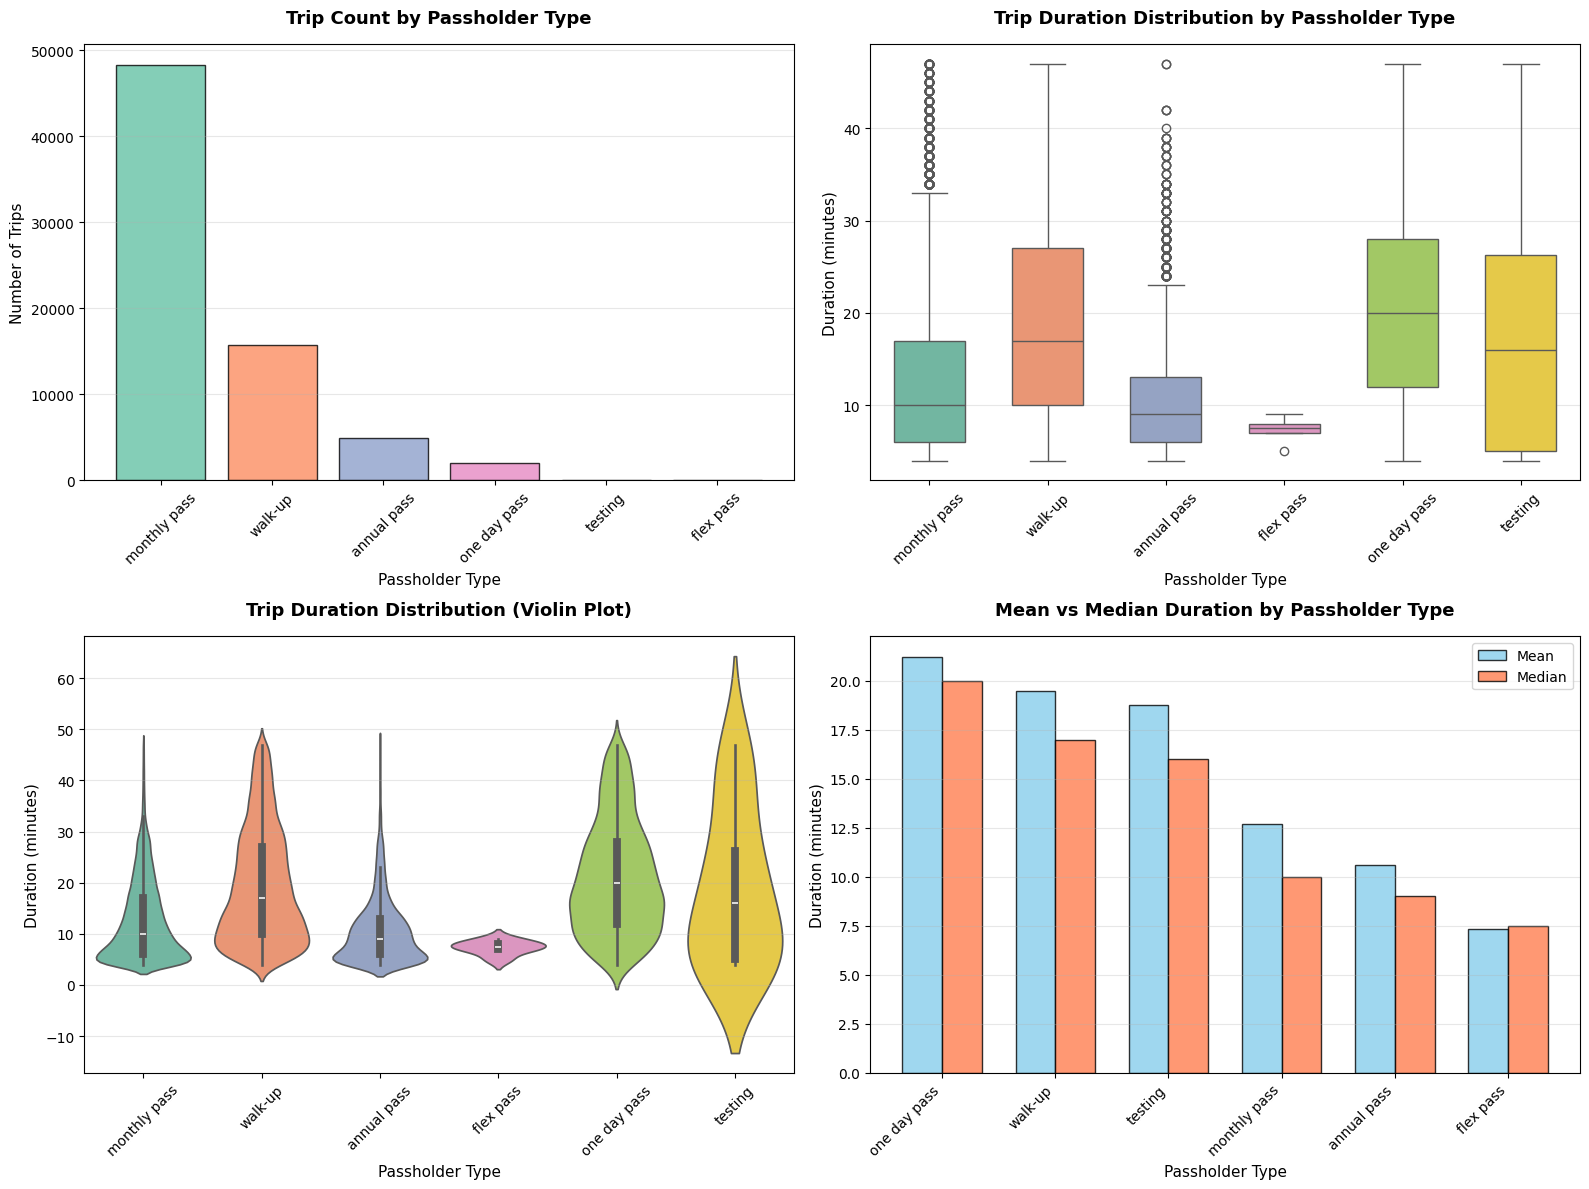

=== STATISTICAL TESTS: Duration by Passholder Type ===

Monthly Pass vs Walk-up:
  t-statistic: -83.5936
  p-value: 0.0000e+00
  Result: Statistically significant (α=0.05)

One-way vs Round-trip:
  t-statistic: -86.7806
  p-value: 0.0000e+00
  Result: Statistically significant (α=0.05)

=== PASSHOLDER TYPE STATISTICS ===
Trip counts by passholder type:
passholder_type
monthly pass    48334
walk-up         15754
annual pass      4979
one day pass     2017
testing            16
flex pass           6
Name: count, dtype: int64

Duration statistics (minutes):
                  mean  median
passholder_type               
one day pass     21.20    20.0
walk-up          19.46    17.0
testing          18.75    16.0
monthly pass     12.70    10.0
annual pass      10.59     9.0
flex pass         7.33     7.5


In [26]:
# Trip counts and duration by passholder type
passholder_counts = df['passholder_type'].value_counts()
avg_duration_by_pass = df.groupby('passholder_type')['duration'].agg(['mean', 'median'])

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Trip count by passholder type
colors_pass = sns.color_palette('Set2', len(passholder_counts))
axes[0, 0].bar(passholder_counts.index, passholder_counts.values, color=colors_pass,
               edgecolor='black', alpha=0.8)
axes[0, 0].set_title('Trip Count by Passholder Type', fontsize=13, fontweight='bold', pad=15)
axes[0, 0].set_xlabel('Passholder Type', fontsize=11)
axes[0, 0].set_ylabel('Number of Trips', fontsize=11)
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(axis='y', alpha=0.3)

# Duration distribution - boxplot
sns.boxplot(x='passholder_type', y='duration', hue='passholder_type', data=df,
            ax=axes[0, 1], palette='Set2', width=0.6, legend=False)
axes[0, 1].set_title('Trip Duration Distribution by Passholder Type', fontsize=13, fontweight='bold', pad=15)
axes[0, 1].set_xlabel('Passholder Type', fontsize=11)
axes[0, 1].set_ylabel('Duration (minutes)', fontsize=11)
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(axis='y', alpha=0.3)

# Duration distribution - violin plot
sns.violinplot(x='passholder_type', y='duration', hue='passholder_type', data=df,
               ax=axes[1, 0], palette='Set2', legend=False)
axes[1, 0].set_title('Trip Duration Distribution (Violin Plot)', fontsize=13, fontweight='bold', pad=15)
axes[1, 0].set_xlabel('Passholder Type', fontsize=11)
axes[1, 0].set_ylabel('Duration (minutes)', fontsize=11)
axes[1, 0].tick_params(axis='x', rotation=45)
axes[1, 0].grid(axis='y', alpha=0.3)

# Mean vs median duration
avg_duration_sorted = avg_duration_by_pass.sort_values('mean', ascending=False)
x_pos = np.arange(len(avg_duration_sorted))
width = 0.35

axes[1, 1].bar(x_pos - width/2, avg_duration_sorted['mean'], width, label='Mean',
               color='skyblue', edgecolor='black', alpha=0.8)
axes[1, 1].bar(x_pos + width/2, avg_duration_sorted['median'], width, label='Median',
               color='coral', edgecolor='black', alpha=0.8)
axes[1, 1].set_title('Mean vs Median Duration by Passholder Type', fontsize=13, fontweight='bold', pad=15)
axes[1, 1].set_xlabel('Passholder Type', fontsize=11)
axes[1, 1].set_ylabel('Duration (minutes)', fontsize=11)
axes[1, 1].set_xticks(x_pos)
axes[1, 1].set_xticklabels(avg_duration_sorted.index, rotation=45, ha='right')
axes[1, 1].legend()
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Statistical comparison of duration by passholder type
print("=== STATISTICAL TESTS: Duration by Passholder Type ===\n")

# Compare Monthly Pass vs Walk-up (two largest groups)
monthly = df[df['passholder_type'] == 'monthly pass']['duration']
walkup = df[df['passholder_type'] == 'walk-up']['duration']

t_stat, p_value = stats.ttest_ind(monthly, walkup)
print(f"Monthly Pass vs Walk-up:")
print(f"  t-statistic: {t_stat:.4f}")
print(f"  p-value: {p_value:.4e}")
print(f"  Result: {'Statistically significant' if p_value < 0.05 else 'Not significant'} (α=0.05)\n")

# Compare One-way vs Round-trip
oneway = df[df['trip_route_category'] == 'one way']['duration']
roundtrip = df[df['trip_route_category'] == 'round trip']['duration']

t_stat, p_value = stats.ttest_ind(oneway, roundtrip)
print(f"One-way vs Round-trip:")
print(f"  t-statistic: {t_stat:.4f}")
print(f"  p-value: {p_value:.4e}")
print(f"  Result: {'Statistically significant' if p_value < 0.05 else 'Not significant'} (α=0.05)")

print("\n=== PASSHOLDER TYPE STATISTICS ===")
print("Trip counts by passholder type:")
print(passholder_counts)
print("\nDuration statistics (minutes):")
print(avg_duration_sorted.round(2))


**Observation**: Most trips are by monthly pass holders. Trip duration patterns differ by passholder type, with “walk-up” and “one day pass” users having higher mean and more variable durations.

### 4.3 Bike Type Analysis
What types of bikes are used? 

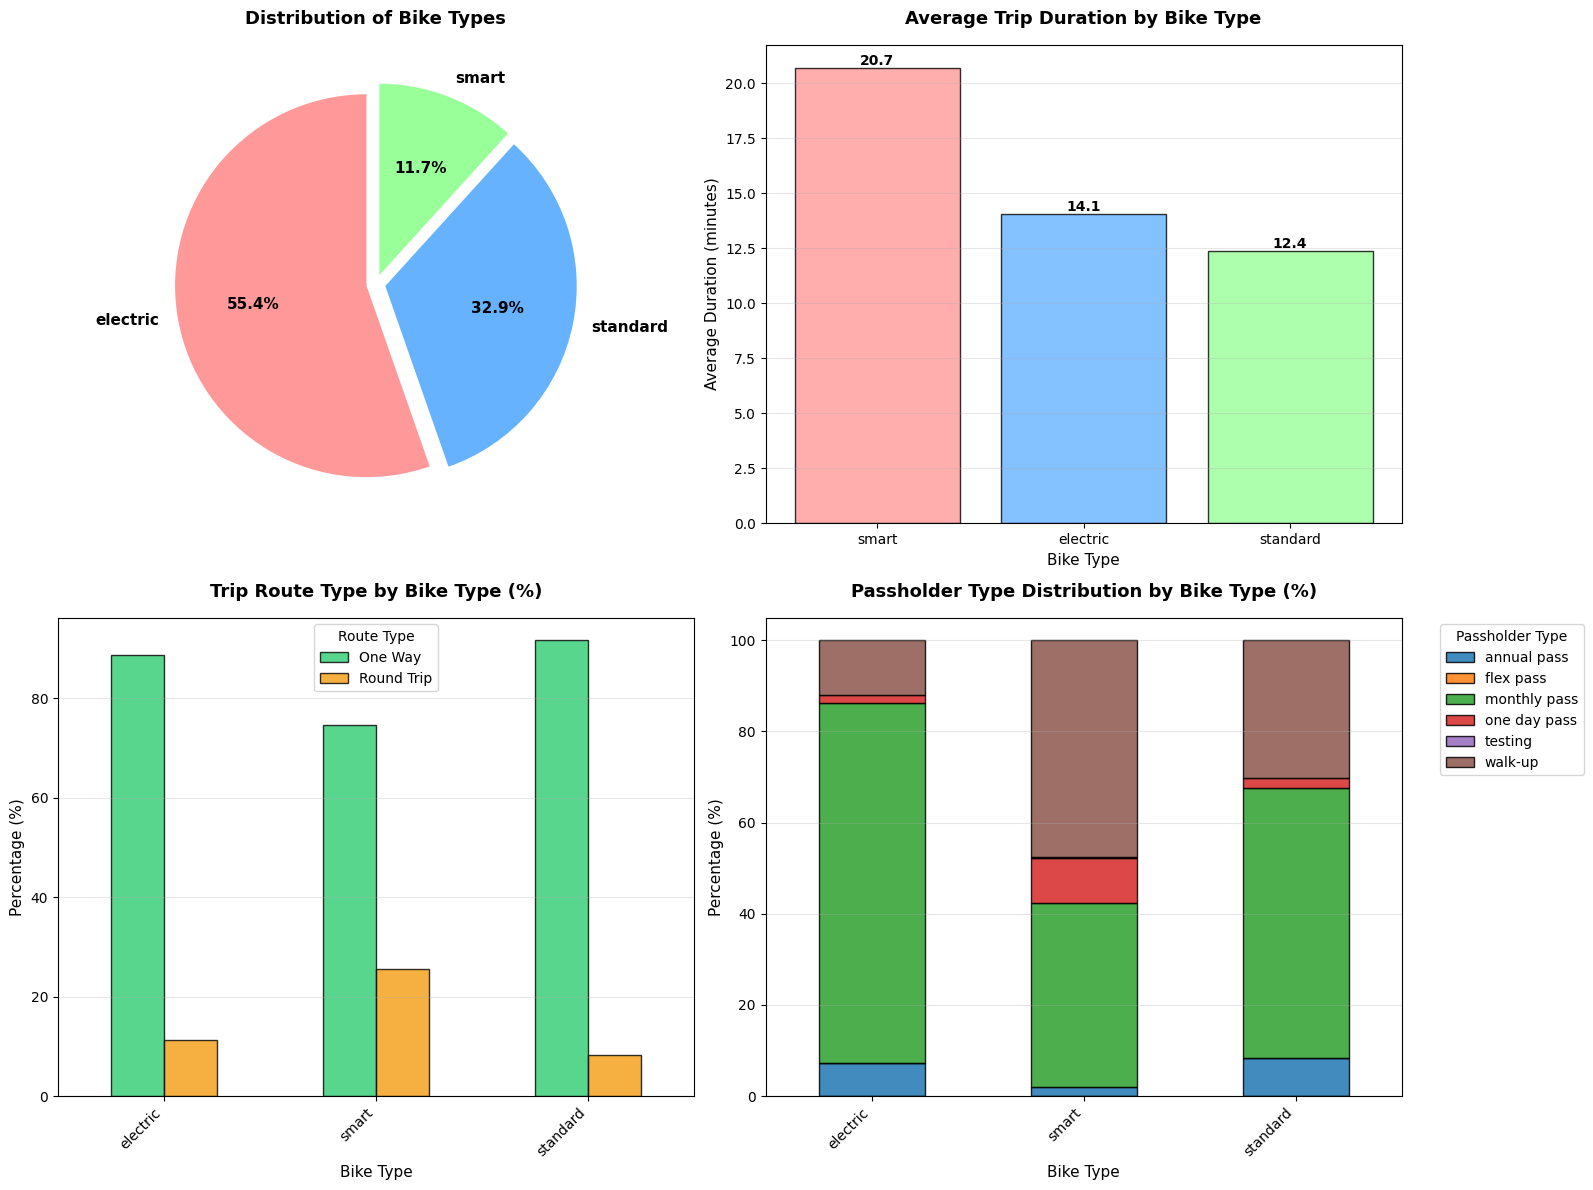


=== BIKE TYPE STATISTICS ===
Bike type distribution:
bike_type
electric    55.36
standard    32.91
smart       11.73
Name: count, dtype: float64

Average duration by bike type:
bike_type
smart       20.70
electric    14.08
standard    12.36
Name: duration, dtype: float64


In [27]:
# Trips and average duration by bike type
bike_type_counts = df['bike_type'].value_counts()
avg_duration_bike = df.groupby('bike_type')['duration'].mean().sort_values(ascending=False)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Bike type distribution pie chart
colors_bike = ['#FF9999', '#66B2FF', '#99FF99']
axes[0, 0].pie(bike_type_counts, labels=bike_type_counts.index, autopct='%1.1f%%',
               startangle=90, colors=colors_bike, explode=(0.05, 0.05, 0.05),
               textprops={'fontsize': 11, 'weight': 'bold'})
axes[0, 0].set_title('Distribution of Bike Types', fontsize=13, fontweight='bold', pad=15)

# Average duration by bike type
bars = axes[0, 1].bar(avg_duration_bike.index, avg_duration_bike.values,
                      color=['#FF9999', '#66B2FF', '#99FF99'], edgecolor='black', alpha=0.8)
axes[0, 1].set_title('Average Trip Duration by Bike Type', fontsize=13, fontweight='bold', pad=15)
axes[0, 1].set_xlabel('Bike Type', fontsize=11)
axes[0, 1].set_ylabel('Average Duration (minutes)', fontsize=11)
axes[0, 1].grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}',
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

# Trip route type by bike type
trip_bike_crosstab = pd.crosstab(df['bike_type'], df['trip_route_category'], 
                                  normalize='index') * 100
trip_bike_crosstab.plot(kind='bar', ax=axes[1, 0], color=['#2ecc71', '#f39c12'],
                        edgecolor='black', alpha=0.8)
axes[1, 0].set_title('Trip Route Type by Bike Type (%)', fontsize=13, fontweight='bold', pad=15)
axes[1, 0].set_xlabel('Bike Type', fontsize=11)
axes[1, 0].set_ylabel('Percentage (%)', fontsize=11)
axes[1, 0].legend(title='Route Type', labels=['One Way', 'Round Trip'])
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=45, ha='right')
axes[1, 0].grid(axis='y', alpha=0.3)

# Passholder type by bike type
pass_bike_crosstab = pd.crosstab(df['bike_type'], df['passholder_type'],
                                  normalize='index') * 100
pass_bike_crosstab.plot(kind='bar', ax=axes[1, 1], stacked=True, edgecolor='black', alpha=0.85)
axes[1, 1].set_title('Passholder Type Distribution by Bike Type (%)', fontsize=13, fontweight='bold', pad=15)
axes[1, 1].set_xlabel('Bike Type', fontsize=11)
axes[1, 1].set_ylabel('Percentage (%)', fontsize=11)
axes[1, 1].legend(title='Passholder Type', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=45, ha='right')
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("\n=== BIKE TYPE STATISTICS ===")
print("Bike type distribution:")
print((bike_type_counts / len(df) * 100).round(2))
print("\nAverage duration by bike type:")
print(avg_duration_bike.round(2))


**Observation:**
Electric bikes are most common, but smart bikes have the longest average trip durations. Most trips are one-way, and monthly pass holders use electric and standard bikes the most.

### 4.4 Weekday vs Weekend Comparison
Do people cycle differently on weekdays vs weekends?

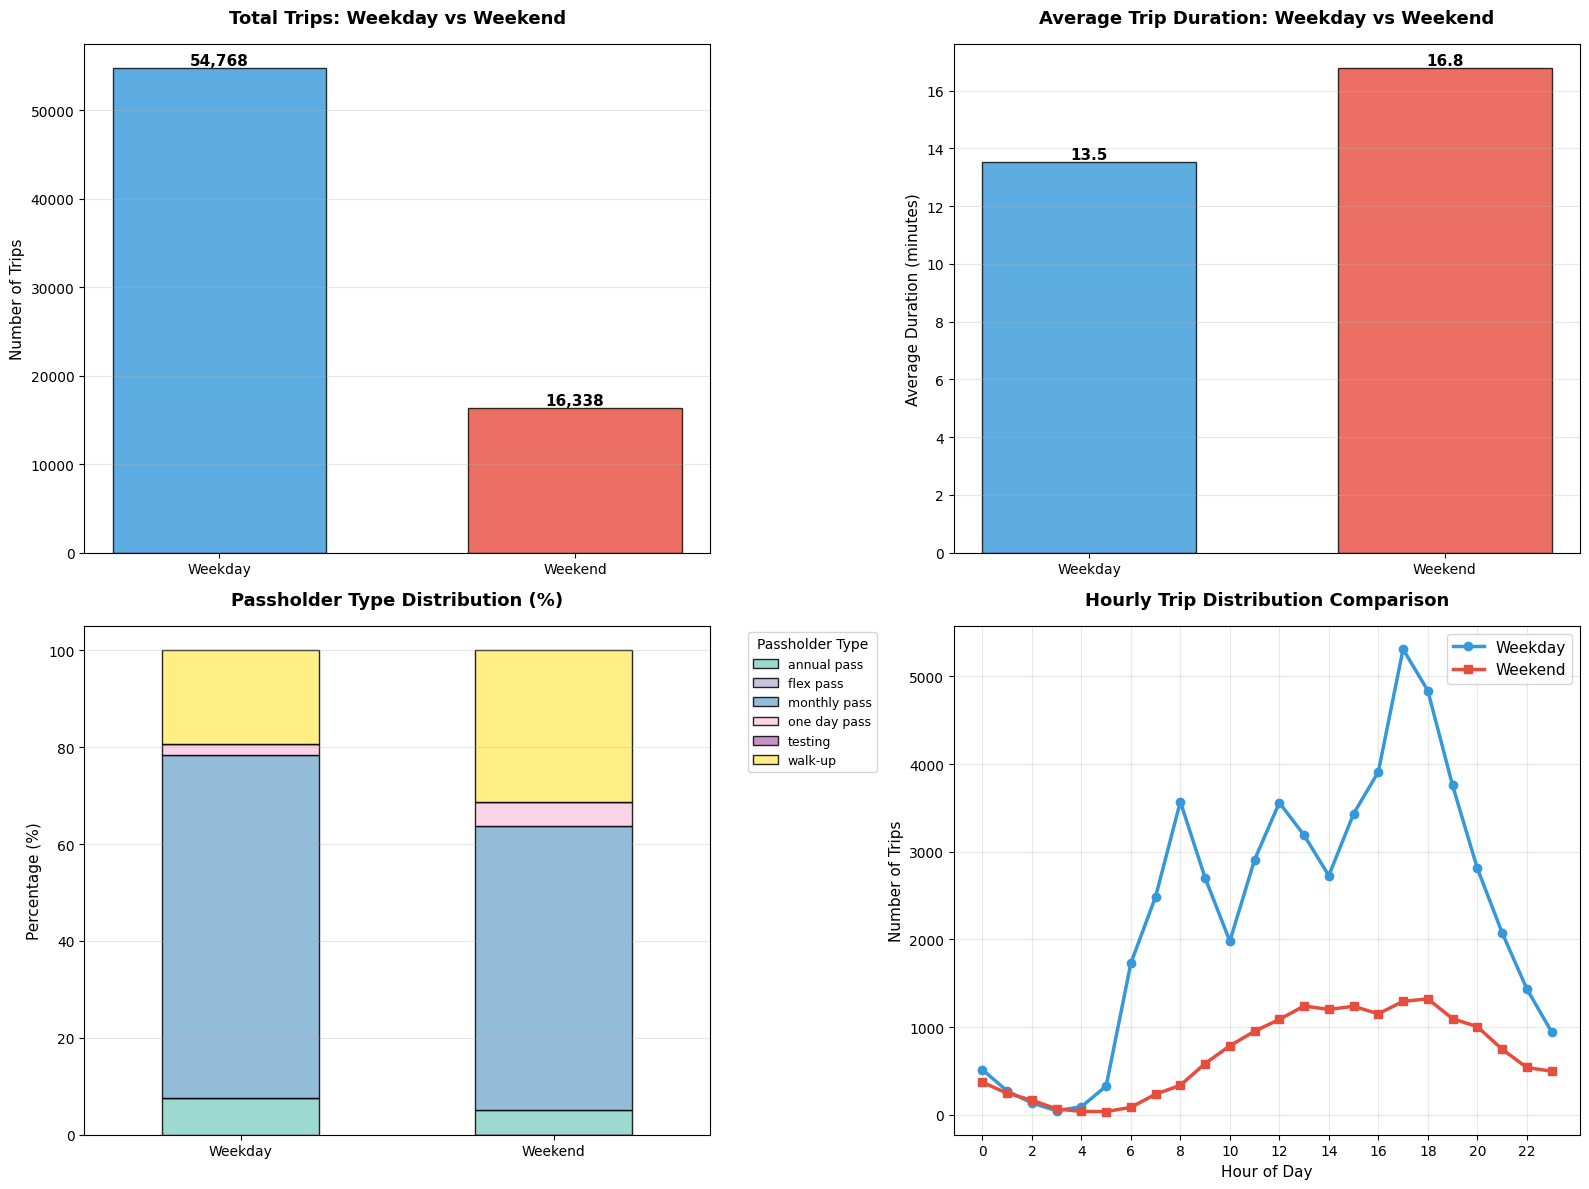


=== WEEKDAY vs WEEKEND INSIGHTS ===
Weekday trips: 54,768
Weekend trips: 16,338
Ratio (Weekday:Weekend): 3.35:1
Weekday avg duration: 13.54 min | Weekend avg duration: 16.78 min
Difference: 3.24 min (weekend is longer)


In [28]:
# Trips count and average duration by weekend
weekend_count = df['weekend'].value_counts().sort_index()
avg_duration_weekend = df.groupby('weekend')['duration'].mean().sort_index()
weekend_labels = ['Weekday', 'Weekend']

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Total trips comparison
bars = axes[0, 0].bar(weekend_labels, weekend_count.values, 
                      color=['#3498db', '#e74c3c'], edgecolor='black', alpha=0.8, width=0.6)
axes[0, 0].set_title('Total Trips: Weekday vs Weekend', fontsize=13, fontweight='bold', pad=15)
axes[0, 0].set_ylabel('Number of Trips', fontsize=11)
axes[0, 0].grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., height, f'{int(height):,}',
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

# Average duration comparison
bars = axes[0, 1].bar(weekend_labels, avg_duration_weekend.values,
                      color=['#3498db', '#e74c3c'], edgecolor='black', alpha=0.8, width=0.6)
axes[0, 1].set_title('Average Trip Duration: Weekday vs Weekend', fontsize=13, fontweight='bold', pad=15)
axes[0, 1].set_ylabel('Average Duration (minutes)', fontsize=11)
axes[0, 1].grid(axis='y', alpha=0.3)

for bar in bars:
    height = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2., height, f'{height:.1f}',
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

# Passholder type distribution
weekend_passholder = pd.crosstab(df['weekend'], df['passholder_type'], normalize='index') * 100
weekend_passholder.index = weekend_labels
weekend_passholder.plot(kind='bar', ax=axes[1, 0], stacked=True, edgecolor='black', 
                        alpha=0.85, colormap='Set3')
axes[1, 0].set_title('Passholder Type Distribution (%)', fontsize=13, fontweight='bold', pad=15)
axes[1, 0].set_ylabel('Percentage (%)', fontsize=11)
axes[1, 0].legend(title='Passholder Type', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=0)
axes[1, 0].grid(axis='y', alpha=0.3)

# Hourly distribution comparison
hour_weekend = df.groupby(['start_hour', 'weekend']).size().unstack(fill_value=0)
hour_weekend.columns = ['Weekday', 'Weekend']

axes[1, 1].plot(hour_weekend.index, hour_weekend['Weekday'], marker='o', linewidth=2.5, 
                markersize=6, label='Weekday', color='#3498db')
axes[1, 1].plot(hour_weekend.index, hour_weekend['Weekend'], marker='s', linewidth=2.5,
                markersize=6, label='Weekend', color='#e74c3c')
axes[1, 1].set_title('Hourly Trip Distribution Comparison', fontsize=13, fontweight='bold', pad=15)
axes[1, 1].set_xlabel('Hour of Day', fontsize=11)
axes[1, 1].set_ylabel('Number of Trips', fontsize=11)
axes[1, 1].legend(fontsize=11)
axes[1, 1].grid(alpha=0.3)
axes[1, 1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

print("\n=== WEEKDAY vs WEEKEND INSIGHTS ===")
print(f"Weekday trips: {weekend_count[False]:,}")
print(f"Weekend trips: {weekend_count[True]:,}")
print(f"Ratio (Weekday:Weekend): {weekend_count[False]/weekend_count[True]:.2f}:1")
print(f"Weekday avg duration: {avg_duration_weekend[False]:.2f} min | Weekend avg duration: {avg_duration_weekend[True]:.2f} min")
print(f"Difference: {avg_duration_weekend[True] - avg_duration_weekend[False]:.2f} min (weekend is longer)")


### 4.5 Route Type Analysis (One-Way vs Round-Trip)
- **Route types tell us about usage patterns** :
- One-way trips suggest commuting (destination-based)
- Round-trips suggest exploration

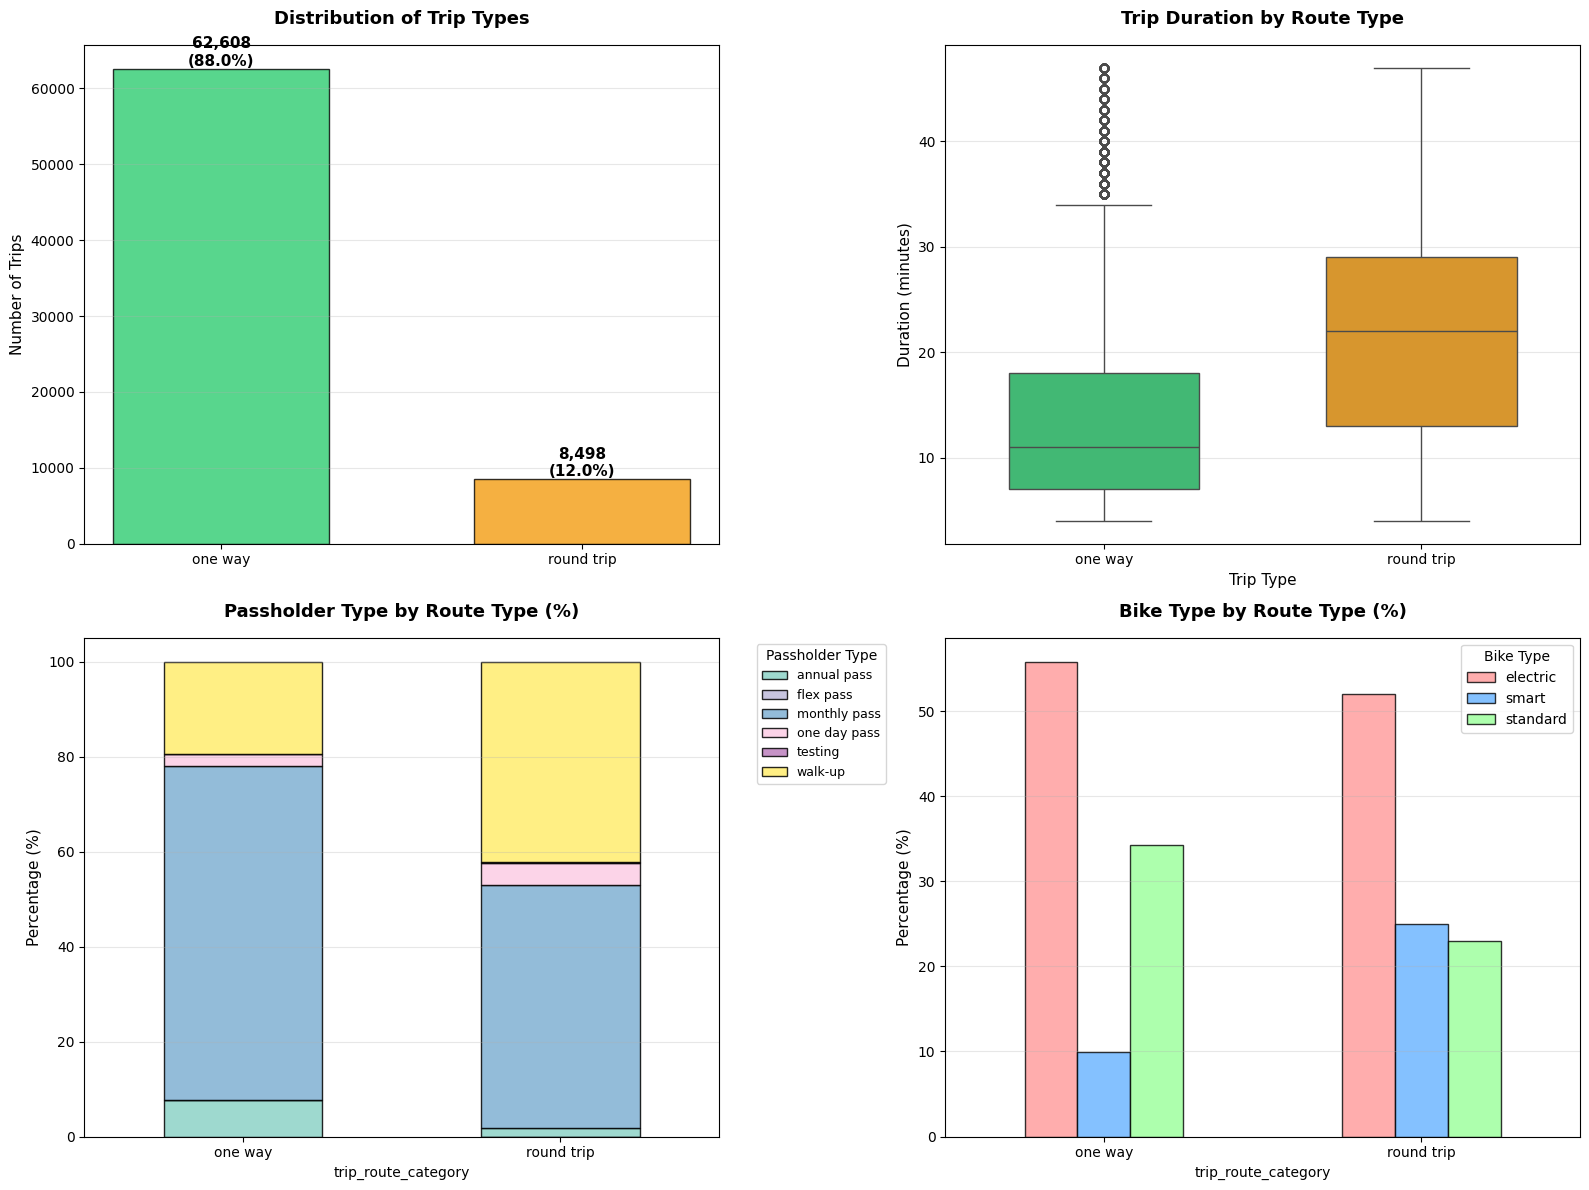


=== ROUTE TYPE STATISTICS ===
One-Way: 62,608 (88.0%)
Round-Trip: 8,498 (12.0%)

Average duration - One-Way: 13.23 min
Average duration - Round-Trip: 22.09 min
Difference: 8.86 min


In [29]:
# Count trips and statistics by route type
route_type_counts = df['trip_route_category'].value_counts()
route_stats = df.groupby('trip_route_category')['duration'].agg(['count', 'mean', 'median'])

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Route type distribution
bars = axes[0, 0].bar(route_type_counts.index, route_type_counts.values, 
                      color=['#2ecc71', '#f39c12'], edgecolor='black', alpha=0.8, width=0.6)
axes[0, 0].set_title('Distribution of Trip Types', fontsize=13, fontweight='bold', pad=15)
axes[0, 0].set_ylabel('Number of Trips', fontsize=11)
axes[0, 0].grid(axis='y', alpha=0.3)

total_trips = route_type_counts.sum()
for bar in bars:
    height = bar.get_height()
    pct = (height / total_trips) * 100
    axes[0, 0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{int(height):,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=11, fontweight='bold')

# Duration by route type
sns.boxplot(x='trip_route_category', y='duration', hue='trip_route_category', data=df,
            ax=axes[0, 1], palette=['#2ecc71', '#f39c12'], width=0.6, legend=False)
axes[0, 1].set_title('Trip Duration by Route Type', fontsize=13, fontweight='bold', pad=15)
axes[0, 1].set_xlabel('Trip Type', fontsize=11)
axes[0, 1].set_ylabel('Duration (minutes)', fontsize=11)
axes[0, 1].grid(axis='y', alpha=0.3)

# Passholder type by route type
route_passholder = pd.crosstab(df['trip_route_category'], df['passholder_type'], normalize='index') * 100
route_passholder.plot(kind='bar', ax=axes[1, 0], stacked=True, edgecolor='black', alpha=0.85, colormap='Set3')
axes[1, 0].set_title('Passholder Type by Route Type (%)', fontsize=13, fontweight='bold', pad=15)
axes[1, 0].set_ylabel('Percentage (%)', fontsize=11)
axes[1, 0].legend(title='Passholder Type', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
axes[1, 0].set_xticklabels(axes[1, 0].get_xticklabels(), rotation=0)
axes[1, 0].grid(axis='y', alpha=0.3)

# Bike type by route type
route_bike = pd.crosstab(df['trip_route_category'], df['bike_type'], normalize='index') * 100
route_bike.plot(kind='bar', ax=axes[1, 1], stacked=False, edgecolor='black', alpha=0.8,
                color=['#FF9999', '#66B2FF', '#99FF99'])
axes[1, 1].set_title('Bike Type by Route Type (%)', fontsize=13, fontweight='bold', pad=15)
axes[1, 1].set_ylabel('Percentage (%)', fontsize=11)
axes[1, 1].legend(title='Bike Type', fontsize=10)
axes[1, 1].set_xticklabels(axes[1, 1].get_xticklabels(), rotation=0)
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics
print("\n=== ROUTE TYPE STATISTICS ===")
print(f"One-Way: {route_type_counts['one way']:,} ({route_type_counts['one way']/total_trips*100:.1f}%)")
print(f"Round-Trip: {route_type_counts['round trip']:,} ({route_type_counts['round trip']/total_trips*100:.1f}%)")
print(f"\nAverage duration - One-Way: {df[df['trip_route_category']=='one way']['duration'].mean():.2f} min")
print(f"Average duration - Round-Trip: {df[df['trip_route_category']=='round trip']['duration'].mean():.2f} min")
print(f"Difference: {df[df['trip_route_category']=='round trip']['duration'].mean() - df[df['trip_route_category']=='one way']['duration'].mean():.2f} min")


### 4.6 Distribution Analysis

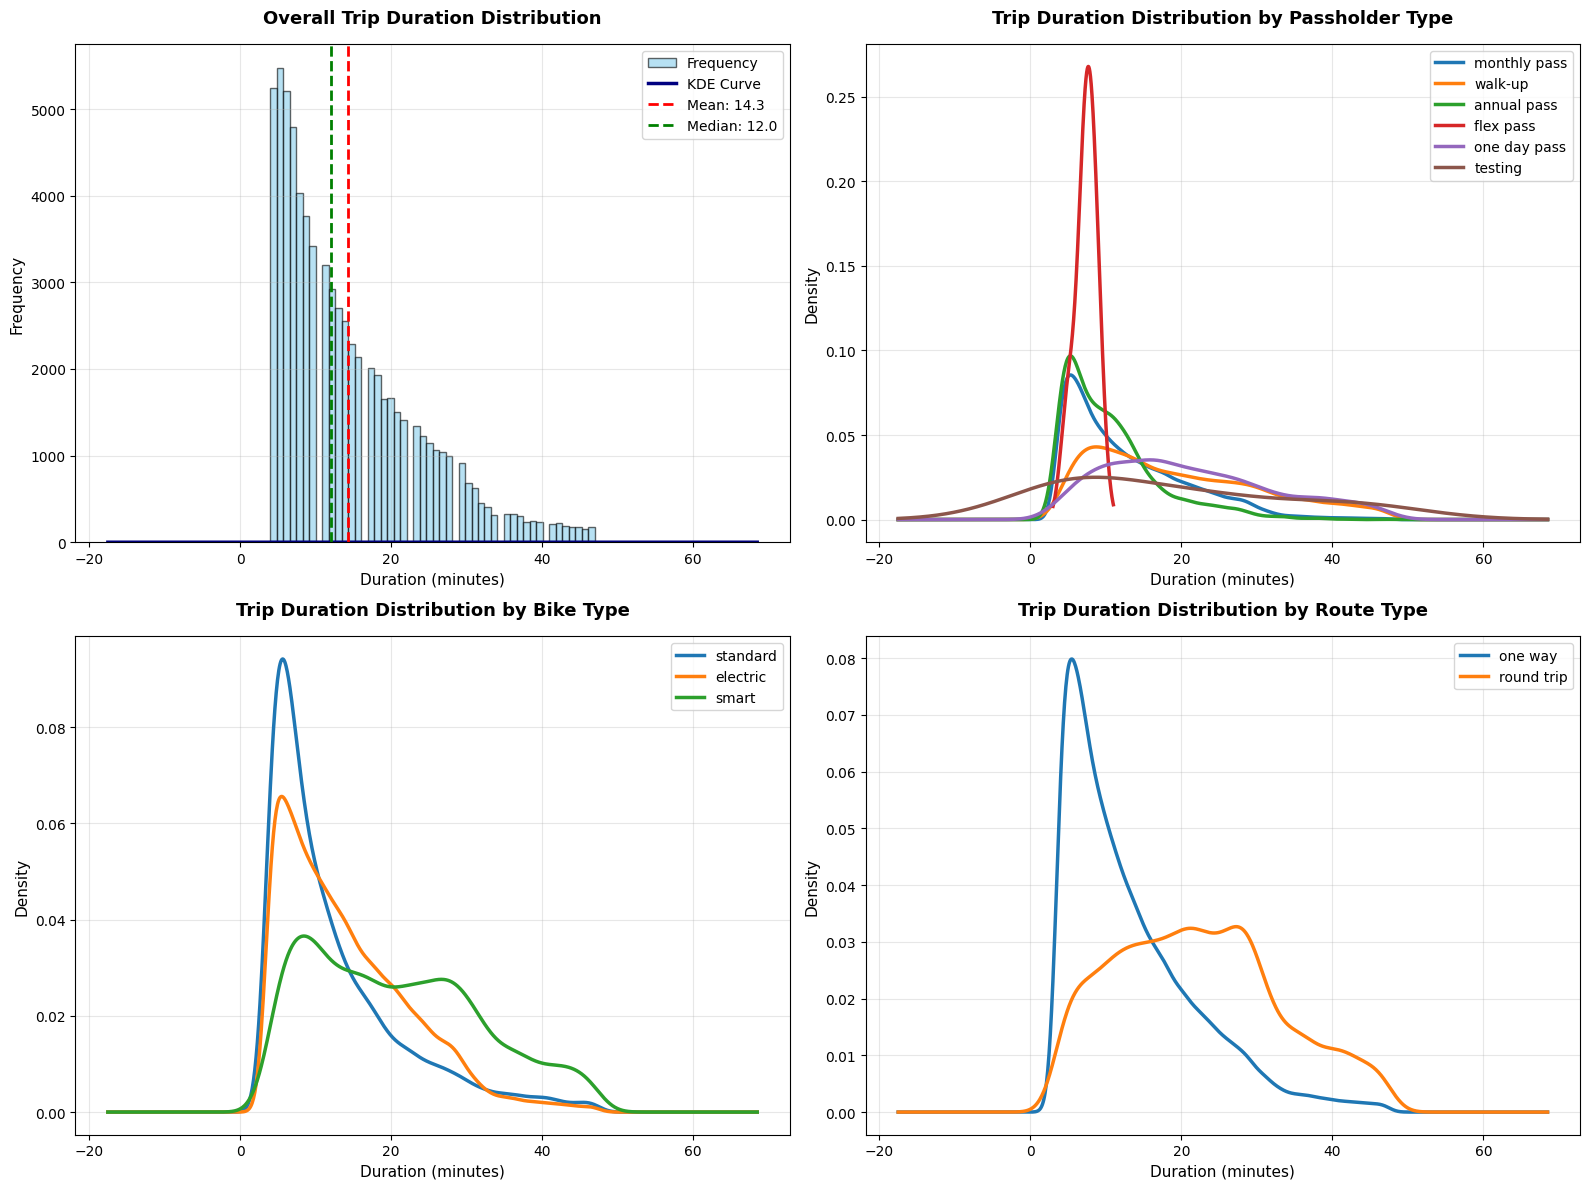


=== DISTRIBUTION STATISTICS ===
Mean: 14.29 min | Median: 12.00 min | Std Dev: 9.29 min
Skewness: 1.15 (positive = right-tailed)


In [30]:
# Compare trip duration distributions across different groups
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Overall duration distribution with stats
ax = axes[0, 0]
df['duration'].plot.hist(bins=50, ax=ax, alpha=0.6, color='skyblue', edgecolor='black', label='Frequency')
df['duration'].plot.kde(ax=ax, secondary_y=False, linewidth=2.5, color='navy', label='KDE Curve')

mean_duration = df['duration'].mean()
median_duration = df['duration'].median()

ax.axvline(mean_duration, color='red', linestyle='--', linewidth=2, label=f'Mean: {mean_duration:.1f}')
ax.axvline(median_duration, color='green', linestyle='--', linewidth=2, label=f'Median: {median_duration:.1f}')

ax.set_title('Overall Trip Duration Distribution', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Duration (minutes)', fontsize=11)
ax.set_ylabel('Frequency', fontsize=11)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# Distribution by passholder type
ax = axes[0, 1]
for pass_type in df['passholder_type'].unique():
    df[df['passholder_type'] == pass_type]['duration'].plot.kde(ax=ax, linewidth=2.5, label=pass_type)

ax.set_title('Trip Duration Distribution by Passholder Type', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Duration (minutes)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# Distribution by bike type
ax = axes[1, 0]
for bike_type in df['bike_type'].unique():
    df[df['bike_type'] == bike_type]['duration'].plot.kde(ax=ax, linewidth=2.5, label=bike_type)

ax.set_title('Trip Duration Distribution by Bike Type', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Duration (minutes)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

# Distribution by route type
ax = axes[1, 1]
for route_type in df['trip_route_category'].unique():
    df[df['trip_route_category'] == route_type]['duration'].plot.kde(ax=ax, linewidth=2.5, label=route_type)

ax.set_title('Trip Duration Distribution by Route Type', fontsize=13, fontweight='bold', pad=15)
ax.set_xlabel('Duration (minutes)', fontsize=11)
ax.set_ylabel('Density', fontsize=11)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Print statistics
print("\n=== DISTRIBUTION STATISTICS ===")
print(f"Mean: {df['duration'].mean():.2f} min | Median: {df['duration'].median():.2f} min | Std Dev: {df['duration'].std():.2f} min")
print(f"Skewness: {df['duration'].skew():.2f} (positive = right-tailed)")


### 4.7 Correlation Analysis & Feature Relationships

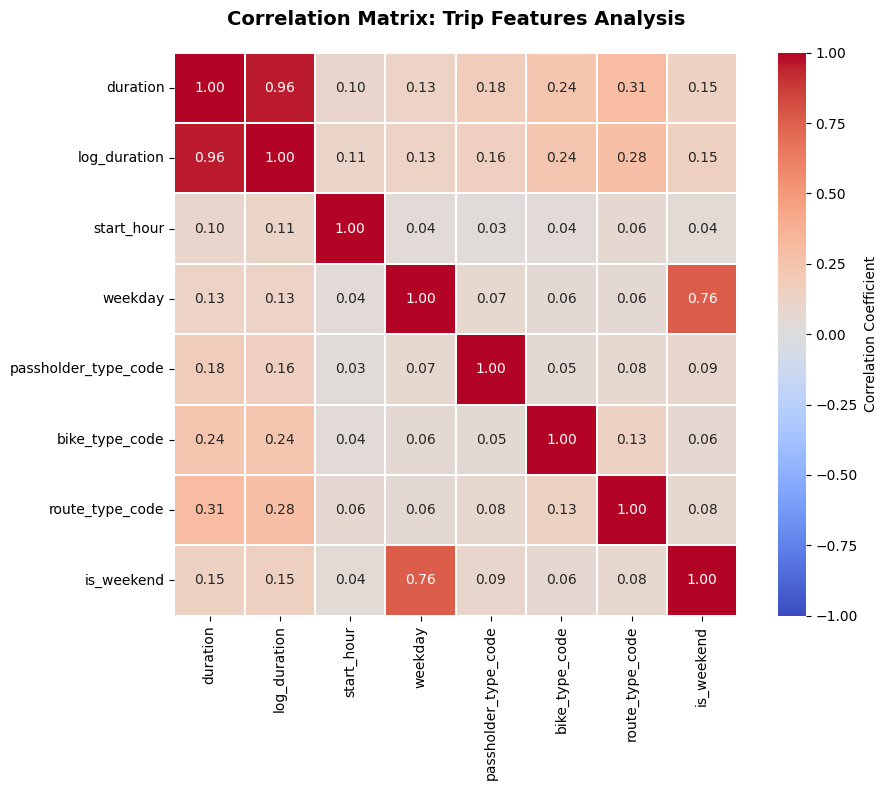


=== CORRELATION INSIGHTS ===

Strongest correlations with duration:
  1. duration: 1.000
  2. log_duration: 0.956
  3. route_type_code: 0.309
  4. bike_type_code: 0.236
  5. passholder_type_code: 0.178
  6. is_weekend: 0.147


In [31]:
# Create dataframe with numeric columns
correlation_df = df[['duration', 'log_duration', 'start_hour', 'weekday']].copy()

# Convert categorical variables to numeric codes
correlation_df['passholder_type_code'] = pd.factorize(df['passholder_type'])[0]
correlation_df['bike_type_code'] = pd.factorize(df['bike_type'])[0]
correlation_df['route_type_code'] = pd.factorize(df['trip_route_category'])[0]
correlation_df['is_weekend'] = df['weekend'].astype(int)

# Calculate correlation matrix
correlation_matrix = correlation_df.corr()

# Create heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1.2, cbar_kws={'label': 'Correlation Coefficient'}, 
            vmin=-1, vmax=1)
plt.title('Correlation Matrix: Trip Features Analysis', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# Print correlation insights
print("\n=== CORRELATION INSIGHTS ===")
print("\nStrongest correlations with duration:")
duration_corr = correlation_matrix['duration'].sort_values(ascending=False)

for i, (feature, corr_value) in enumerate(duration_corr.head(6).items()):
    print(f"  {i+1}. {feature}: {corr_value:.3f}")


**Observation** : Trip duration is weakly correlated with bike type, route type, and passholder type, but strongly correlated with its log transformation. Other features show low correlation with each other.

## 4.Final Summary Section

In [32]:
print("=== DATA CLEANING SUMMARY ===")
print(f"Original records: {len(df_original)}")
print(f"Records after cleaning: {len(df):,}")
print(f"Records removed: {len(df_original) - len(df):,} ({(len(df_original)-len(df))/92124*100:.2f}%)")
print(f"\nFinal missing values: {df.isnull().sum().sum()}")
print(f"Final dataset shape: {df.shape}")

=== DATA CLEANING SUMMARY ===
Original records: 92124
Records after cleaning: 71,106
Records removed: 21,018 (22.81%)

Final missing values: 0
Final dataset shape: (71106, 21)


## 5.Conclusion

This EDA cleaned and analyzed 92,124 LA Metro Bike Share trips, removing 22.81% of records due to data quality issues (missing coordinates, invalid values, outliers).

**Key Findings:**
- **Temporal:** Peak usage 5 PM weekdays; Tuesday busiest (3.35:1 weekday/weekend ratio)
- **Users:** Monthly pass holders (68%) take shorter trips (4.4 min avg); casual users ride significantly longer (7.0 min, p<0.001)
- **Equipment:** Electric bikes preferred (55.4%); one-way trips dominate (88%)
- **Statistical:** Weekend trips significantly longer (+3.24 min); strong correlation between route type (0.309) and duration

**Data Quality:**
- Standardized datatypes; removed 3 ghost stations (3000, 4285, 4286)
- Domain rules (3-1440 min) + IQR filtering reduced skewness to 1.15
- Engineered temporal features for pattern detection

The cleaned dataset (71,106 records) supports predictive modeling and station utilization analysis.


## References
- Metro Los Angeles (2025) **Metro Bike Share Trip Data**. Available at: https://bikeshare.metro.net/about/data/
- **Pandas (2025)** Available at: https://pandas.pydata.org/docs/
- **NumPy (2025)** Available at: https://numpy.org/doc/
- **Matplotlib (2025)** Available at: https://matplotlib.org/stable/index.html
- **Seaborn (2025)** Available at: https://seaborn.pydata.org/


## Peer To Peer Review : 

**Summary:**

The data cleaning and analysis process is well-structured in the notebook provided by Ahmed. His code is well-structured, beginning from loading data to dealing with missing values and cleaning data. Analysis of his code reveals that removal of trips containing incomplete coordinate data, as well as trips containing invalid duration data, is incorporated to make data more reliable for analysis.

**Clarity and Correctness:**
Function as well as variable naming is consistent, and Ahmed follows methods from pandas, numpy, seaborn, as well as sklearn well. One area for improvement is in dealing with NaNs as well as infinity, where chaining replace, dropna, as well as fillna could be more reproducibly expressed.

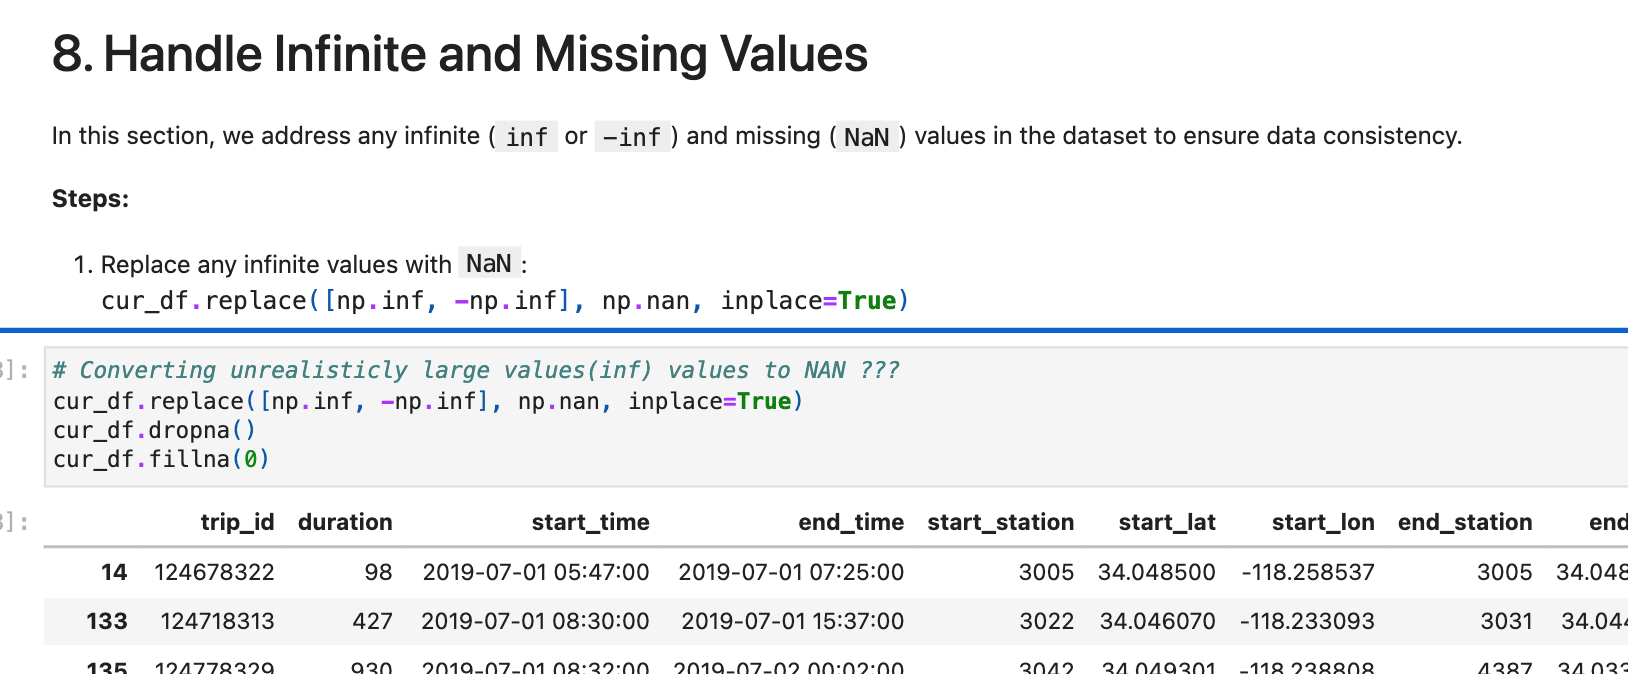

**Analytical Depth:**
Analysis incorporates thorough visual exploration histograms, boxplots, and KDE plots show the distribution and effect of cleaning. Outlier removal is systematic, though the stricter IQR=1 threshold should be explicitly justified. Feature engineering is robust, extracting time-based features and calculating distance using the Haversine formula. Statistical comparisons of trip durations between user groups (t-tests) are performed and interpreted, connecting EDA with inferential analysis.

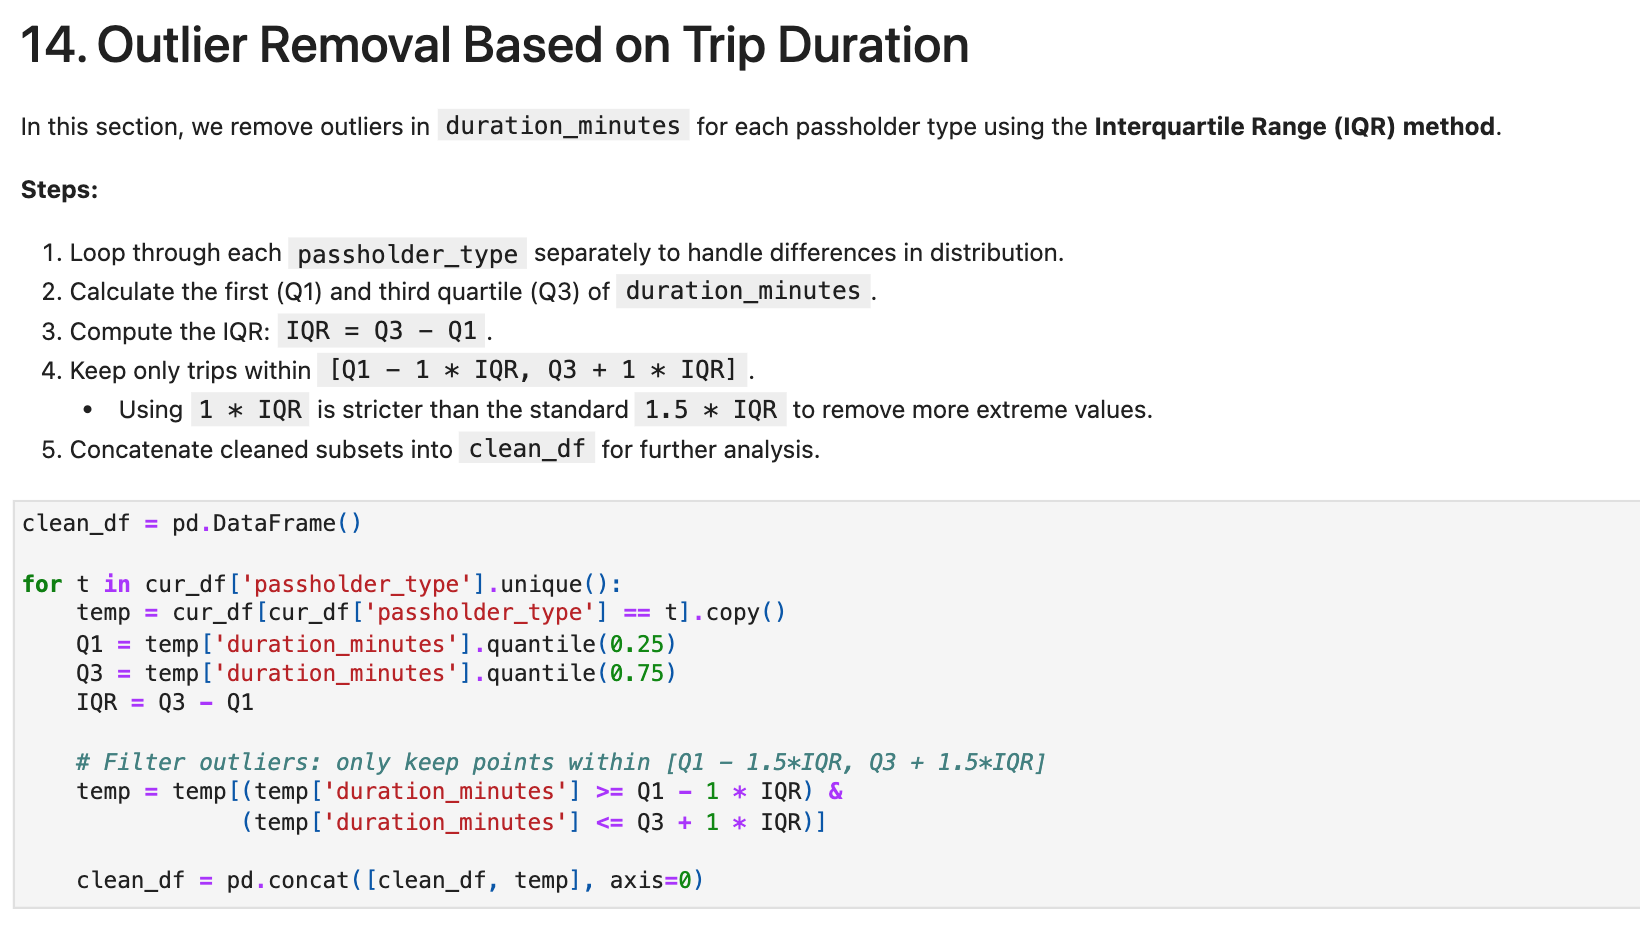

**Explanation and Feedback:**

Markdown provides context, but key findings from plots and tests could be interpreted more fully. Expanding discussion on statistical significance and operational insights would add value. DataFrame naming during processing should be more consistent.

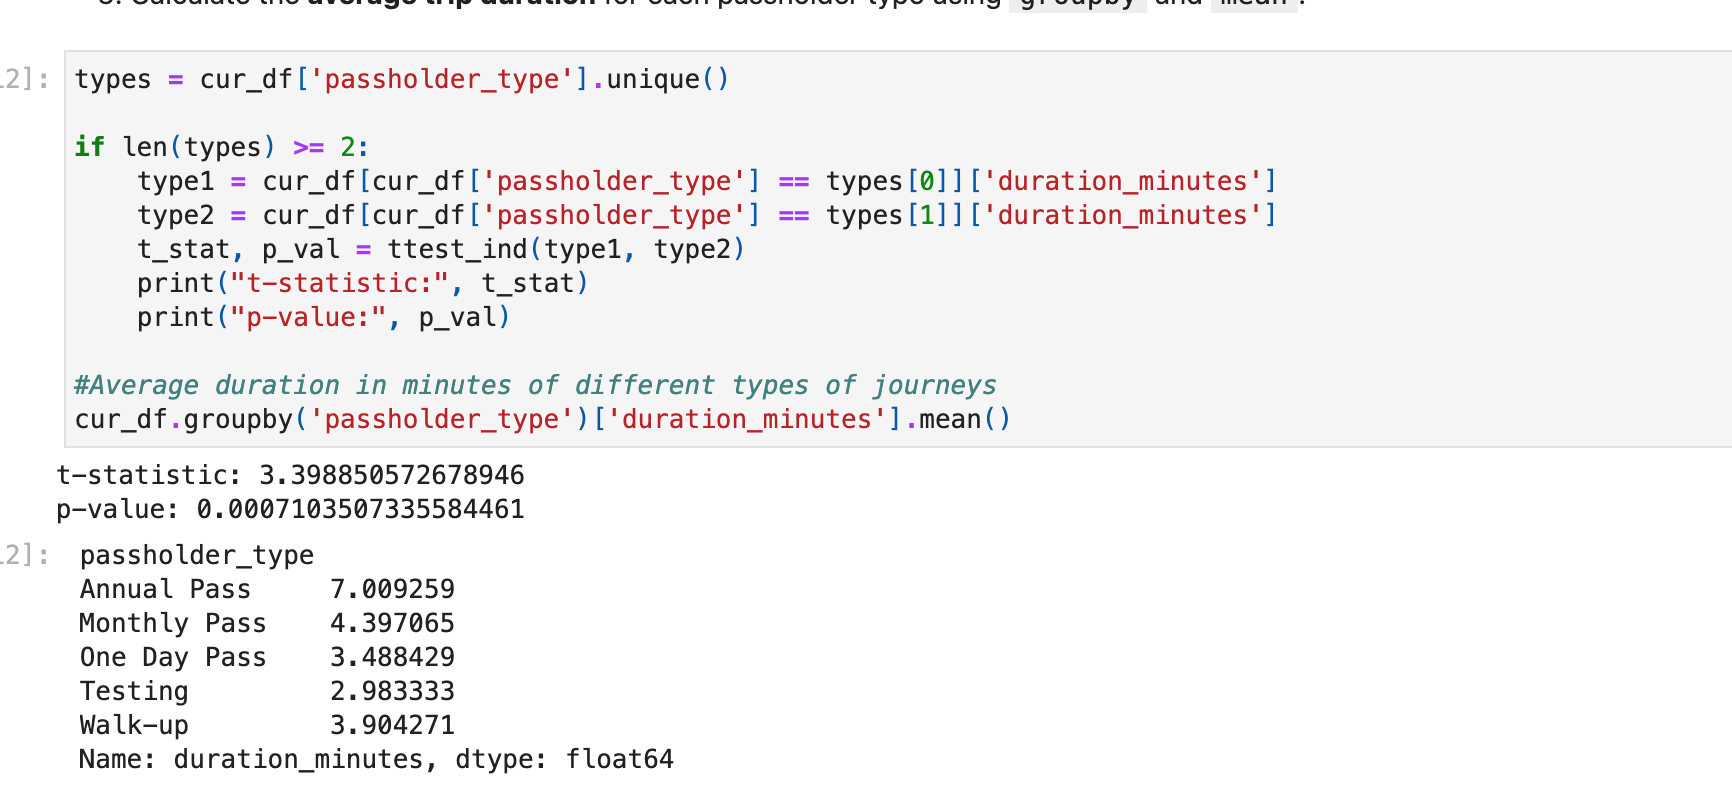
**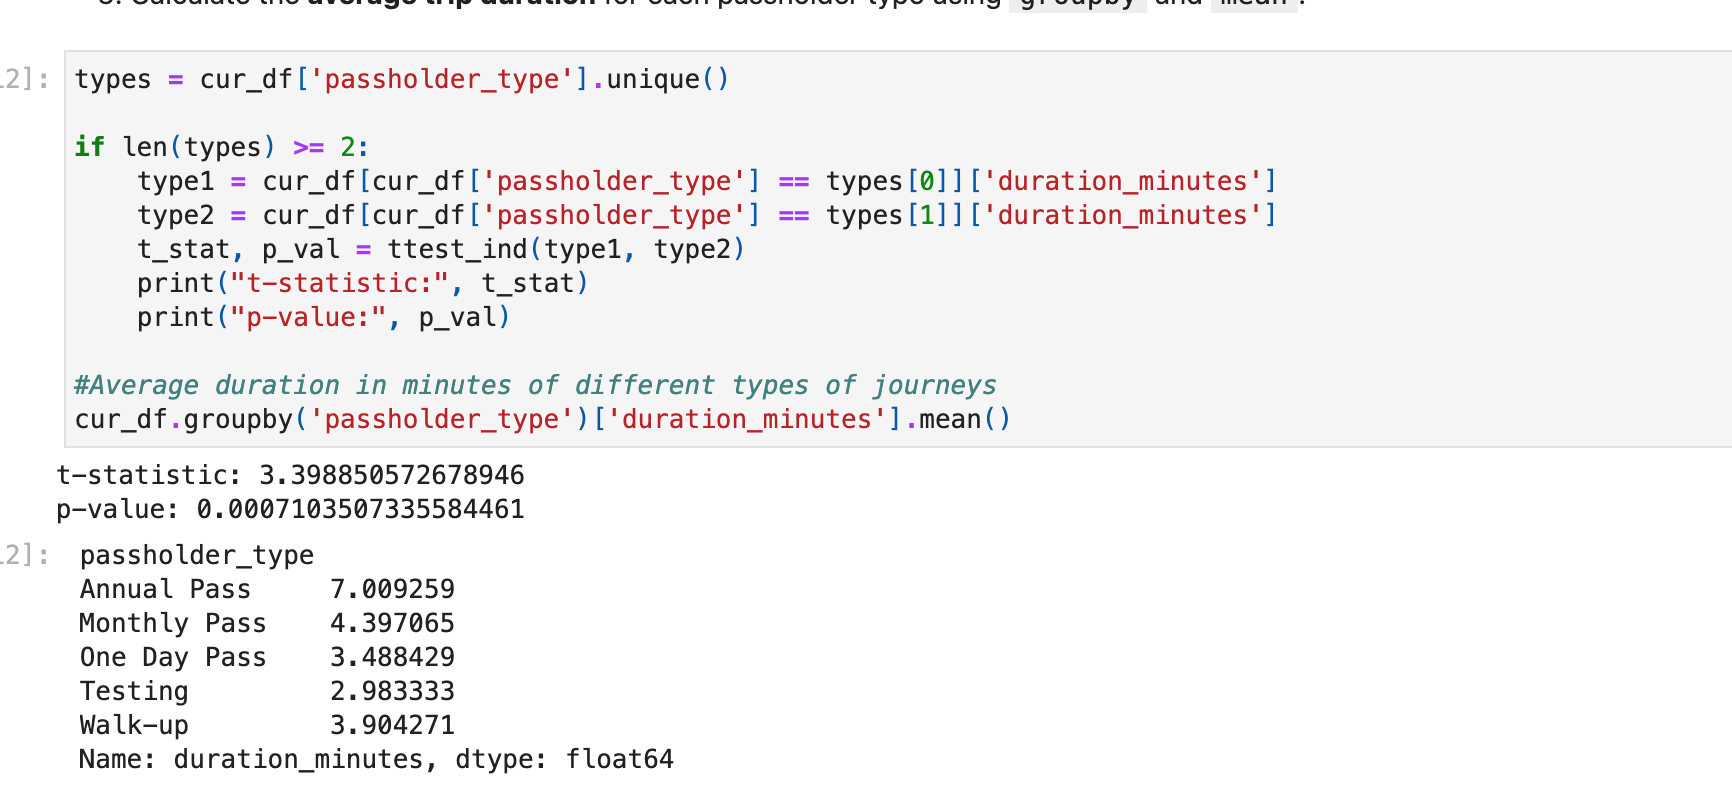

**Actionable Feedback:**

- Clarify the logic for outlier and missing value treatment.
- Interpret key visuals and statistical outputs to highlight insights.
- Standardize DataFrame naming for workflow clarity.
- 
#### conclusion 

In conclusion the notebook is technically strong, systematic, and well-explained. Additional insight and detailed rationale would enhance the analytical impact.
